# Cross-disciplinary exchange in biological agent-based modelling

This notebook analyses a bibliometric dataset of Web of Science records containing the terms **"agent-based model*"** and/or **"individual-based model*"** in the article title, abstract, or author keywords.

The article records are classified in two staged using an LLM:
1. **Biology** or **Not Biology**.
2. Biological articles are further classified into exactly one biological subfield:
   - Ecology
   - Epidemiology
   - Oncology
   - Other Biology


The notebook reproduces the analyses and results presented in the manuscript but for a smaller dataset, namely:

### Data analysis

1. Terminology: The number of articles using ABM only, IBM only, or both in title/abstract/keywords over time.
2. The fraction of articles in each field and biological subfield overall.
3. The number of articles in each biological subfield over time.
4. The fraction of articles in each biologucal subfield over time.

### Results

1. **Cross-disciplinary citation patterns.**
    - Citation network (absolute citation counts)
    - Pie charts (citation percentages)
2. **Cross-subfield overlap in ORCID-identified authors.**
    - For ABMs specifically.
    - For other biological modelling techniques (ODEs, PDEs) where data are collected using a keyword search.


---

## Project setup

In [ ]:
# -----------------------------
# 1. Import libraries
# Used to:
# - handle file and directory paths
# - search and extract text using regular expressions
# - create dictionaries with automatic default values
# - manipulate and analyse tabular data
# - create plots and figures
# -----------------------------

from pathlib import Path
import re
from collections import defaultdict

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt 
from matplotlib_venn import venn3
from matplotlib.patches import FancyArrowPatch, Circle


# -----------------------------
# 2. Define project paths
# -----------------------------

# Input the Web of Science dataset 
INPUT_FILE = Path("data/simulated_data.txt")

# Store all outputs into a specified folder
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Define the output folders
OUTPUT_DIRS = {
    "analysis": OUTPUT_DIR / "data_analysis_outputs",
    "terminology": OUTPUT_DIR / "terminology_outputs",
    "citations": OUTPUT_DIR / "citation_field_overlap_outputs",
    "orcid": OUTPUT_DIR / "orcid_field_overlap_outputs",
    "orcid_keyword": OUTPUT_DIR / "orcid_keyword_field_overlap_outputs",
}

# Create the output folders
for folder in OUTPUT_DIRS.values():
    folder.mkdir(parents=True, exist_ok=True)

# Create shortcut variables for output folders
ANALYSIS_OUTPUT_DIR = OUTPUT_DIRS["analysis"]
TERMINOLOGY_OUTPUT_DIR = OUTPUT_DIRS["terminology"]
CITATION_OUTPUT_DIR = OUTPUT_DIRS["citations"]
ORCID_OUTPUT_DIR = OUTPUT_DIRS["orcid"]
ORCID_KEYWORD_OUTPUT_DIR = OUTPUT_DIRS["orcid_keyword"]


# -----------------------------
# 3. Define subfields and colours
# -----------------------------

# The four biological subfields used throughout the analysis.
FIELDS = [
    "ecology",
    "epidemiology",
    "oncology",
    "other",
]

# All categories present in the classified dataset.
CATEGORIES = FIELDS + [
    "biology",
    "not_biology",
]

"""
# Colours used for the biological subfields.
colour_map = {
    "ecology": "#388E3C", # "#66c266",         # light green
    "epidemiology": "#f1a340",    # orange
    "oncology": "#998ec3",        # purple
    "other": "#888888", # "#d3d3d3",           # light gray
    "not_biology": "#4d4d4d",     # dark gray
}
"""

colour_map = {
    "ecology": "#388E3C",        # Dark green
    "epidemiology": "#D97721",   # Burnt orange
    "oncology": "#4267A5",       # Deep blue
    "other": "#888888",          # Dark grey
    "not_biology": "#4d4d4d",    # Very dark grey
}

## Load and parse Web of Science records

In [2]:
# ----------------------------
# 1. Read WoS-style records and split into individual records
# ----------------------------

def extract_records(filename):

    records = [] # creates a list
    with open(filename, "r", encoding="utf-8") as f: 
        current = [] 
        recording = False 

        for line in f: 
            line = line.rstrip() #remove any whitespace and any newlines 

            # Each record begins with PT J
            if line == "PT J": 
                current = [line] 
                recording = True 
                continue 

            if recording: 
                current.append(line) 

                # Each record ends with ER
                if line == "ER": 
                    records.append(current) 
                    recording = False 

    return records 


# ----------------------------
# 2. Extract and return the value from a field tag from a record
# ----------------------------

def extract_field(record, field):

    for line in record: 
        # Look for the requested field (e.g., KA or PY)
        if line.startswith(field + " "): 
            return line[len(field) + 1 :].strip()  #remove the field tag and the space from the returned value

    # Return None if the field does not exist in the record.
    return None 


# ----------------------------
# 3. Create records to a DataFrame
# ----------------------------

# Read the Web of Science records from the input file
records = extract_records(INPUT_FILE)

rows = []

for rec in records: 
    # Extract the publication year (PY) and the LLM-assigned category (KA)
    year = extract_field(rec, "PY")
    cls  = extract_field(rec, "KA")

    # Skip records with missing values
    if year is None or cls is None:
        continue

    # Append a dictionary so that each row will look like e.g., {"Year": 2005, "Class": "oncology"}
    rows.append({ 
        # Convert Year into an integer
        "Year": int(year), 
        # Convert categories into lowercase for consistency
        "Class": cls.lower()
    })

# Convert the extracted data into a pandas DataFrame (2 columns: Year and Class)
df = pd.DataFrame(rows)

# Display the first few rows of the DataFrame
df.head()

,Year,Class
0,2023,epidemiology
1,2023,ecology
2,2023,ecology
3,2023,other
4,2023,epidemiology


---

# Figure 1

## Number of articles over time per subfield

In [3]:
# ----------------------------
# 1. Count articles per year and per biological subfield
# ----------------------------
counts = ( #
    df.groupby(["Year", "Class"]) 
      .size()  
      .reset_index(name="Articles") 
)


# ----------------------------
# 2. Ensure all years in full range (include years even if they have no articles)
# ----------------------------
full_year_range = range(df["Year"].min(), df["Year"].max() + 1)
# Get all unique classes, sorted alphabetically
all_classes = sorted(df["Class"].unique()) 

# Create a multi-index that contains all combinations of years and biological subfield
index = pd.MultiIndex.from_product(
    [full_year_range, all_classes],
    names=["Year", "Class"]
)

# Fill missing year-subfield combinations with zero article counts
counts = (
    counts.set_index(["Year", "Class"])
          .reindex(index, fill_value=0)
          .reset_index() 
)


# ----------------------------
# 3. Create a yearly summary table
# ----------------------------
pivot = counts.pivot(
    index="Year", 
    columns="Class",
    values="Articles"
)

# Order the biological subfields alphabetically
pivot = pivot.reindex(sorted(pivot.columns), axis=1)


# ----------------------------
# 4. Save summary table
# ----------------------------
summary_table = pivot.reset_index()
summary_table.to_excel(ANALYSIS_OUTPUT_DIR / "biology_class_count_per_year.xlsx", index=False)
print("\nSaved summary table to: biology_class_count_per_year.xlsx")


Saved summary table to: biology_class_count_per_year.xlsx


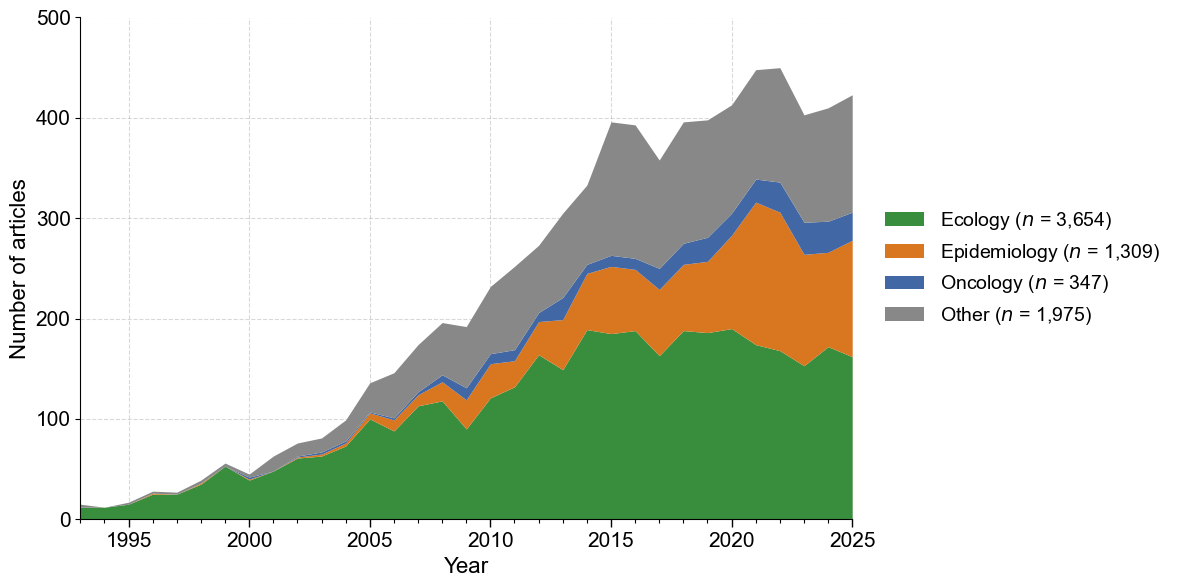

In [4]:
# --------------------------------------------- 
# 1. Prepare yearly article counts for plotting 
# ---------------------------------------------

# Restrict the analysis to years from 1993 onwards
pivot_counts_filtered = pivot[pivot.index >= 1993]

# Keep only the four biological subfields
pivot_counts_filtered = pivot_counts_filtered[FIELDS]

from matplotlib import font_manager

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 11,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "pdf.fonttype": 42,
})


# ---------------------------------------------
# 2. Create stacked area chart
# ---------------------------------------------

fig, ax = plt.subplots(figsize=(20, 6))

pivot_counts_filtered.plot(
    kind='area',  # Changed from 'bar' to 'area'
    stacked=True,
    color=[colour_map[c] for c in pivot_counts_filtered.columns],
    linewidth=0,  # No black outlines
    legend=False,
    ax=ax
)

# Legend (outside the plot)
labels = {
    "ecology": "Ecology",
    "epidemiology": "Epidemiology",
    "oncology": "Oncology",
    "other": "Other"
}

handles = ax.collections[:len(pivot_counts_filtered.columns)]

"""
ax.legend(
    handles=handles,
    labels=[labels[c.lower()] for c in pivot_counts_filtered.columns],
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    fontsize=14,
    frameon=False
)
"""

# Legend (outside the plot)
labels = {
    c: f"{c.capitalize()} ($n$ = {pivot_counts_filtered[c].sum():,})"
    for c in pivot_counts_filtered.columns
}

handles = ax.collections[:len(pivot_counts_filtered.columns)]

ax.legend(
    handles=handles,
    labels=[labels[c] for c in pivot_counts_filtered.columns],
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    fontsize=14,
    frameon=False
)

ax.set_box_aspect(0.65)


# --------------------------------------------- 
# 3. Format axes 
# ---------------------------------------------

plt.ylabel("Number of articles", fontsize=16)
plt.xlabel("Year", fontsize=16)

"""
# Label every second year
years = pivot_counts_filtered.index

ax.set_xticks(years[::5])
ax.set_xticklabels(years[::5], rotation=90, fontsize=15)
"""

# Major ticks: labelled every 4 years starting at 1993
ax.set_xticks(range(1995, 2026, 5))
ax.set_xticklabels(range(1995, 2026, 5), rotation=0, fontsize=15)

# Minor ticks: every year, without labels
ax.set_xticks(range(1993, 2026), minor=True)

# Make both major and minor ticks visible
ax.tick_params(axis='x', which='major', length=6, width=1)
ax.tick_params(axis='x', which='minor', length=3, width=0.8)

#ax.set_ylim(bottom=0)
ax.set_ylim(0, 500)
ax.set_yticks(range(0, 501, 100))
ax.set_xlim(pivot_counts_filtered.index.min(), pivot_counts_filtered.index.max())
ax.tick_params(axis='y', labelsize=15)

# Remove top and right border of the figure
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Add faint horizontal dotted lines behind the bars
ax.set_axisbelow(True)
ax.yaxis.grid(True, linestyle='--', color='grey', alpha=0.3)
ax.xaxis.grid(True, linestyle='--', color='grey', alpha=0.3)


# --------------------------------------------- 
# 4. Save figure 
# ---------------------------------------------

plt.tight_layout()
plt.savefig(ANALYSIS_OUTPUT_DIR / "biology_class_count_over_time.pdf", bbox_inches="tight")
plt.show()

---

# **Result 1** (Figure 2)

## Terminology: The number of articles using ABM only, IBM only, or both in title/abstract/keywords over time.

In [5]:
# ============================================================
# ABM VS IBM TERMINOLOGY SEARCH - ANALYSIS
# ============================================================

# -----------------------------
# 1. Define keywords and matching functions
# -----------------------------

# Accepted variations of "agent-based model".
ABM_KEYWORDS = [
    "agent based model", 
    "agent-based model", 
    "agent- based model",
    "agent -based model", 
    "agent - based model", 
    "agentbased model",
    "agent-based-model", 
    "agent based-model"
]

# Accepted variations of "individual-based model".
IBM_KEYWORDS = [
    "individual based model", 
    "individual-based model", 
    "individual- based model",
    "individual -based model", 
    "individual - based model", 
    "individualbased model",
    "individual-based-model", 
    "individual based-model"
]

# Return True if the text contains any of the supplied keywords, or else return False
def contains_keyword(text, keywords):

    if not text:
        return False
    
    text = text.lower() # Convert to lowercase
    text = re.sub(r"[^\w\s-]", "", text) # Remove punctuation for consistent matching

    return any(keyword in text for keyword in keywords)


# Check for ABM specific keywords
def contains_abm(text):
    return contains_keyword(text, ABM_KEYWORDS)


# Check for IBM specific keywords
def contains_ibm(text):
    return contains_keyword(text, IBM_KEYWORDS)


# -----------------------------
# 2. Count ABM/IBM articles per year
# -----------------------------

# Define the article fields and subfields to analyse
TERM_GROUPS = {
    #"Biology": ["ecology", "epidemiology", "oncology", "other"],
    "Biology": FIELDS,
    "Not biology": ["not_biology"],
    "Ecology": ["ecology"],
    "Epidemiology": ["epidemiology"],
    "Oncology": ["oncology"],
    "Other": ["other"],
}

term_tables = {}

# Process each article subfield separately
for group_name, group_classes in TERM_GROUPS.items():

    # Store yearly counts for each termionology category
    year_counts = defaultdict(lambda: {
        "Only_ABM": 0,
        "Only_IBM": 0,
        "ABM_or_IBM": 0,
        "ABM_and_IBM": 0
    })

    for rec in records:
        cls = extract_field(rec, "KA")
        year_str = extract_field(rec, "PY")

        # Skip articles with incomplete records
        if cls is None or year_str is None:
            continue
        
        # Convery cls to lower case
        cls = cls.lower()

        # Skip articles outside the current class
        if cls not in group_classes: 
            continue

        # Skip articles with an invalid PY
        if not year_str.isdigit():
            continue

        # Convert string into integer, e.g., "2021" -> 2021
        year = int(year_str)

        # Combine the searchable text fields (title, abstract, author keywords) into one chunk of text
        # "" puts a space between each piece of text
        search_text = " ".join([
            extract_field(rec, "TI") or "",
            extract_field(rec, "AB") or "",
            extract_field(rec, "DE") or "",
        ])

        # Check for ABM keywords
        abm = contains_abm(search_text)

        # Check for IBM keywords
        ibm = contains_ibm(search_text)

        # Convert the yearly counts into a DataFrame
        # Just ABM
        if abm and not ibm:
            year_counts[year]["Only_ABM"] += 1
        # Just IBM
        if ibm and not abm:
            year_counts[year]["Only_IBM"] += 1
        # Total
        if abm or ibm:
            year_counts[year]["ABM_or_IBM"] += 1
        # Contains both ABM and IBM
        if abm and ibm:
            year_counts[year]["ABM_and_IBM"] += 1

    yearly_rows = []

    # Sorts years in chronological order and create one row per Year
    for y in sorted(year_counts.keys()):
        yearly_rows.append({
            "Year": y,
            "Only_ABM": year_counts[y]["Only_ABM"],
            "Only_IBM": year_counts[y]["Only_IBM"],
            "ABM_or_IBM": year_counts[y]["ABM_or_IBM"],
            "ABM_and_IBM": year_counts[y]["ABM_and_IBM"],
        })

    # Convert the yearly counts lists into a DataFrame sorted by Year
    term_df = pd.DataFrame(yearly_rows).sort_values("Year")

    # Store the DataFrame for this group.
    term_tables[group_name] = term_df   


# -----------------------
# 3. Save as excel file: each subfield is a separate sheet
# -----------------------

terminology_excel_path = (
    TERMINOLOGY_OUTPUT_DIR / "abm_ibm_terminology_counts.xlsx"
)

with pd.ExcelWriter(terminology_excel_path) as writer:
    for group_name, term_df in term_tables.items():
        term_df.to_excel(
            writer,
            sheet_name=group_name,
            index=False
        )

print(f"Saved terminology tables to {terminology_excel_path.name}")

Saved terminology tables to abm_ibm_terminology_counts.xlsx


### Plot

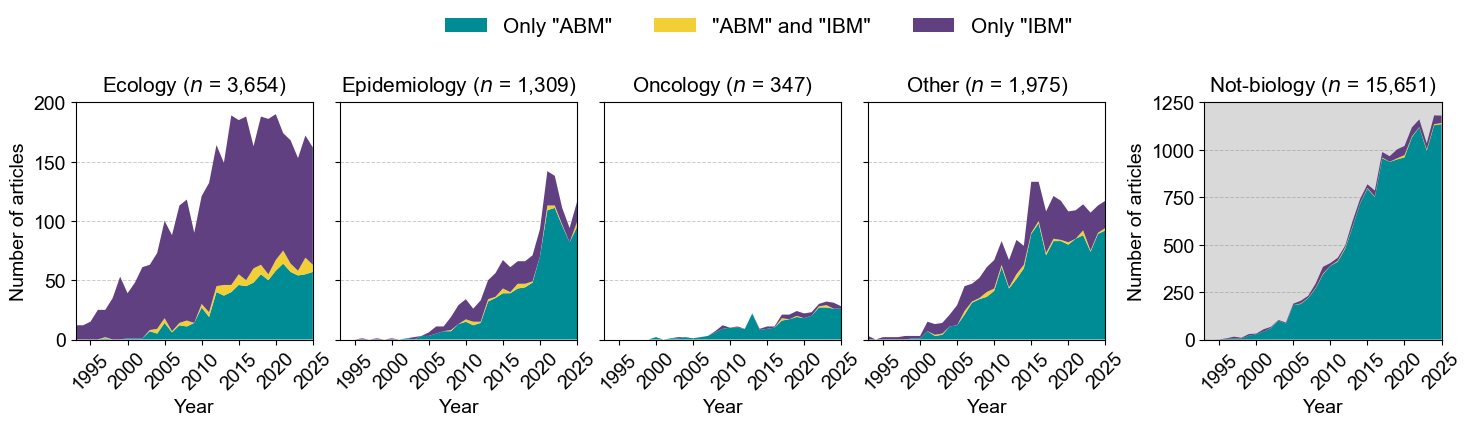

In [62]:

# ============================================================
# ABM VS IBM TERMINOLOGY SEARCH - STACKED AREA PLOT
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 15,
    "axes.labelsize": 14,
    "axes.titlesize": 15,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 15,
    "pdf.fonttype": 42,
})

# ---------------------------------------------
# Colours for plots
# ---------------------------------------------

term_colours = {
    "Only_ABM": "#008C95",
    "Only_IBM": "#604080",
    "ABM_and_IBM": "#F2CF35"
}

# ---------------------------------------------
# Create figure
# ---------------------------------------------

fig, axs = plt.subplots(
    1, 5,
    figsize=(18, 4.5),
    sharex=True,
    sharey=False
)

# Share y-axis across the four biological subfields
for ax in axs[1:4]:
    ax.sharey(axs[0])

# ---------------------------------------------
# Order and titles
# ---------------------------------------------

plot_order = [
    "Ecology",
    "Epidemiology",
    "Oncology",
    "Other",
    "Not biology"
]

axes = dict(zip(plot_order, axs))

# Shade the Not-biology panel light grey
axes["Not biology"].set_facecolor("#d9d9d9")

title_labels = {
    "Ecology": "Ecology",
    "Epidemiology": "Epidemiology",
    "Oncology": "Oncology",
    "Other": "Other",
    "Not biology": "Not-biology"
}

# ---------------------------------------------
# Plot yearly terminology counts
# ---------------------------------------------

for title, ax in axes.items():

    ax.set_box_aspect(1)

    df_term = term_tables[title].copy()
    df_term = df_term[df_term["Year"] >= 1993]

    # Total number of articles
    n_articles = int(
        df_term[
            ["Only_ABM", "ABM_and_IBM", "Only_IBM"]
        ].sum().sum()
    )

    # Add missing years
    all_years = pd.DataFrame({
        "Year": range(1993, 2026)
    })

    df_term = all_years.merge(
        df_term,
        on="Year",
        how="left"
    ).fillna(0)

    # ---------------------------------------------
    # Stacked area plot
    # ---------------------------------------------

    ax.set_xlim(1993, 2025)

    ax.stackplot(
        df_term["Year"],
        df_term["Only_ABM"],
        df_term["ABM_and_IBM"],
        df_term["Only_IBM"],
        labels=[
            'Only "ABM"',
            '"ABM" and "IBM"',
            'Only "IBM"'
        ],
        colors=[
            term_colours["Only_ABM"],
            term_colours["ABM_and_IBM"],
            term_colours["Only_IBM"]
        ],
        alpha=1
    )

    if title == "Not biology":
        ax.set_ylim(0, 1250)
        ax.set_yticks([0, 250, 500, 750, 1000, 1250])
    else:
        ax.set_ylim(0, 200)
        ax.set_yticks([0, 50, 100, 150, 200])

    # ---------------------------------------------
    # Titles and axis labels
    # ---------------------------------------------

    ax.set_xlabel("Year")

    ax.set_title(
        f"{title_labels[title]} ($n$ = {n_articles:,})",
        pad=8
    )

    if title == "Ecology" or title == "Not biology":

        ax.set_ylabel("Number of articles")

    elif title == "Not biology":

        ax.set_ylabel("")
        ax.yaxis.set_label_position("left")
        ax.yaxis.tick_left()

        ax.tick_params(
            axis="y",
            left=True,
            labelleft=True,
            right=False,
            labelright=False
        )

    else:

        ax.set_ylabel("")

        ax.tick_params(
            axis="y",
            left=True,
            labelleft=False
        )

    # ---------------------------------------------
    # Grid
    # ---------------------------------------------

    ax.set_axisbelow(True)

    """
    ax.grid(
        axis="y",
        linestyle="-",
        color="lightgrey",
        alpha=0.4,
        linewidth=0.7
    )
    """

    ax.grid(
        axis="y",
        linestyle="--",
        color="#808080" if title == "Not biology" else "#808080",
        alpha=0.4 if title == "Not biology" else 0.4,
        linewidth=0.7
    )

    # ---------------------------------------------
    # Year ticks and labels
    # ---------------------------------------------
    """
    tick_years = list(range(1993, 2026, 2))
    label_years = list(range(1993, 2026, 4))

    ax.set_xticks(tick_years)

    ax.set_xticklabels([
        str(year) if year in label_years else ""
        for year in tick_years
    ])

    ax.tick_params(
        axis="x",
        rotation=90
    )
    """

    # ---------------------------------------------
    # Year ticks and labels
    # ---------------------------------------------

    ax.set_xticks([1995, 2000, 2005, 2010, 2015, 2020, 2025])

    ax.tick_params(
        axis="x",
        rotation=45,
    )

    for label in ax.get_xticklabels():
        label.set_ha("center")

# ---------------------------------------------
# Adjust subplot positions
# ---------------------------------------------

# Apply layout first, reserving space for legend
plt.tight_layout(rect=[0, 0, 1, 0.96])

# Keep the original panel dimensions
positions = [ax.get_position().frozen() for ax in axs]

# Horizontal gaps, in figure coordinates
biology_gap = 0.015
not_biology_gap = 0.055

# Centre the complete group within the figure
panel_widths = [pos.width for pos in positions]

total_width = (
    sum(panel_widths)
    + 3 * biology_gap
    + not_biology_gap
)

start_x = (1 - total_width) / 2

current_x = start_x

for i, ax in enumerate(axs):

    pos = positions[i]

    ax.set_position([
        current_x,
        pos.y0,
        pos.width,
        pos.height
    ])

    current_x += pos.width

    if i < 3:
        current_x += biology_gap
    elif i == 3:
        current_x += not_biology_gap

# ---------------------------------------------
# Shared legend
# ---------------------------------------------

handles, labels = axes["Ecology"].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.0),
    ncol=3,
    frameon=False
)

# ---------------------------------------------
# Save figure
# ---------------------------------------------

plt.savefig(
    TERMINOLOGY_OUTPUT_DIR / "ABM_VS_IBM_line_plot.pdf",
    bbox_inches="tight"
)

plt.show()


In [80]:
# ---------------------------------------------
# Titles inside plots (top-left)
# ---------------------------------------------

title_bg = (
    "#d9d9d9" if title == "Not biology" else "white"
)

ax.text(
    0.03, 0.97,
    f"{title_labels[title]} ($n$ = {n_articles:,})",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=14,
    bbox=dict(
        facecolor=title_bg,
        edgecolor="none",
        alpha=1,
        pad=2
    ),
    zorder=10
)

Text(0.03, 0.97, 'Not-biology ($n$ = 15,651)')

---

# **Result 2** (Figure 3): Cross-disciplinary citation patterns

This section identifies citations within our classified articles in the four biological subfields (ecology, epidemiology, oncology and other biology). 

Reference files are searched for Web of Science identifiers, which are matched against the classified dataset to construct citation networks for absolute citation counts, pie charts for citation percentages, and summary tables.

In [7]:
# ============================================================
# SET-UP
# ============================================================

# Folders containing reference article metadata for each biological subfield
REFERENCE_FOLDERS = {
    "ecology": "all ecology references (1993up)",
    "epidemiology": "all epidemiology references (1993up)",
    "oncology": "all oncology references (1993up)",
    "other": "all other references (1993up)",
}

# Publication years to exclude from the analysis
EXCLUDED_YEARS = {2026}

In [8]:
# ============================================================
# LOAD THE WEB OF SCIENCE RECORDS
# ============================================================

# Load the WoS records and organise them by the unique identifiers (UT)
# Returns:
#         ut_lookup: dictionary mapping each UT to its biological subfield and publication year
#         article_counts: dictionary containing number of records in each biological subfield

def load_category_records(input_file):

    ut_lookup = {}
    article_counts = {field: 0 for field in FIELDS}

    path = Path(input_file)

    if not path.exists():
        raise FileNotFoundError(
            f"Missing classified file: {input_file}"
        )

    # Read the WoS records
    category_records = extract_records(path)

    for record in category_records:
        ut = extract_field(record, "UT")
        year = extract_field(record, "PY")
        field = extract_field(record, "KA")

        # Skip records missing required information
        if ut is None or year is None or field is None:
            continue

        field = field.lower().strip()

        # Keep only the biological subfields included in the analysis
        if field not in FIELDS:
            continue

        # Convert the publication year to an integer
        try:
            year = int(year)
        except ValueError:
            continue

        # Exclude the specified publication years
        if year in EXCLUDED_YEARS:
            continue

        ut_lookup[ut] = {
            "field": field,
            "year": year,
        }

        article_counts[field] += 1

    return ut_lookup, article_counts

ut_lookup, article_counts = load_category_records(INPUT_FILE)

print(f"Loaded {len(ut_lookup)} classified article UTs")

for field, count in article_counts.items():
    print(f"{field}: {count}")

Loaded 7285 classified article UTs
ecology: 3654
epidemiology: 1309
oncology: 347
other: 1975


In [9]:
# ============================================================
# CITATION EXTRACTION
# ============================================================

# Convert WOS_XXXXXXXX.txt filename to WOS:XXXXXXXX
# E.g., WOS_1234 contains the WoS metadata of all articles that are cited by WOS:1234
def filename_to_ut(filename):
    return filename.replace(".txt", "").replace("WOS_", "WOS:")


# Extract the cited WoS UT identifiers from the reference file
def extract_cited_uts(reference_text):
    return re.findall(r"WOS:\S+", reference_text)


# Build the citation links between the articles
# Returns a dataframe with each row a citation, and columns citing_ut, citing_field, citing_year, cited_ut, cited_field, cited_year            
def build_citation_links(ut_lookup, reference_folders):

    rows = []
    missing_folder_count = 0
    skipped_files = 0

    for citing_field, folder in reference_folders.items():
        folder_path = Path(folder)

        # Skip the subfields for which the reference folder cannot be found
        if not folder_path.exists():
            print(f"WARNING: missing reference folder: {folder}")
            missing_folder_count += 1
            continue

        # Each reference file represents one citing article
        for path in folder_path.glob("*.txt"):
            citing_ut = filename_to_ut(path.name)

            # Only process articles that are in the biology dataset
            if citing_ut not in ut_lookup:
                skipped_files += 1
                continue

            # Retrieve the subfield and the publication year of the citing article
            citing_info = ut_lookup[citing_ut]
            citing_year = citing_info["year"]

            # Read the reference file and extract the UTs of all cited articles
            reference_text = path.read_text(encoding="utf-8", errors="replace")
            cited_uts = extract_cited_uts(reference_text)

            for cited_ut in cited_uts:

                # Keep only citations to articles within classified biology dataset
                if cited_ut not in ut_lookup:
                    continue

                # Retrieve the subfield and publication year of the cited article 
                cited_info = ut_lookup[cited_ut]

                # Store one row for each citing-cited relationship
                rows.append({
                    "citing_ut": citing_ut,
                    "citing_field": citing_field,
                    "citing_year": citing_year,
                    "cited_ut": cited_ut,
                    "cited_field": cited_info["field"],
                    "cited_year": cited_info["year"],
                })

    df = pd.DataFrame(rows)

    print(f"Citation links retained within classified dataset: {len(df)}")
    print(f"Reference folders missing: {missing_folder_count}")
    print(f"Reference files skipped because citing UT was not classified: {skipped_files}")

    return df

df = build_citation_links(
    ut_lookup,
    REFERENCE_FOLDERS,
)

if df.empty:
    raise RuntimeError(
        "No citation links found. Check file paths and UT formatting."
    )

df.head()

Citation links retained within classified dataset: 22541
Reference folders missing: 0
Reference files skipped because citing UT was not classified: 0


,citing_ut,citing_field,citing_year,cited_ut,cited_field,cited_year
0,WOS:000306736000002,ecology,2012,WOS:000288099800012,ecology,2011
1,WOS:000306736000002,ecology,2012,WOS:A1995RE22500005,other,1995
2,WOS:001490084200001,ecology,2025,WOS:001392998600001,ecology,2025
3,WOS:001490084200001,ecology,2025,WOS:000912254100001,ecology,2023
4,WOS:001490084200001,ecology,2025,WOS:000690827900001,ecology,2021


In [10]:
# ============================================================
# CREATE SUMMARY TABLES
# ============================================================

# Create the citation matrix where rows=citing fields, columns=cited fields
def make_citation_matrix(df):

    # Count the citation linkjs between every pair of biological subfields
    matrix = pd.crosstab(df["citing_field"], df["cited_field"])

    # Ensure all subfields are present and appear in consistent order
    matrix = matrix.reindex(index=FIELDS, columns=FIELDS, fill_value=0)
    return matrix


# Convert the citation matrix to row-wise percentages to see the distribution of citations made by one biological subfield across all cited subfields
def make_fraction_matrix(matrix):
    return matrix.div(matrix.sum(axis=1), axis=0) * 100

#def make_fraction_matrix(matrix):
#    fraction = matrix.div(matrix.sum(axis=1), axis=0) * 100
#    return fraction.fillna(0)


# Calculate the expected citation counts
def make_expected_matrix(matrix):
    row_totals = matrix.sum(axis=1) # Total citations made by each subfield
    col_totals = matrix.sum(axis=0) # Total citations received by each subfield
    grand_total = matrix.values.sum() # Total number of citation links across all subfields

    # Calculate the expected number of citations for each subfield pair if citing field and cited field were independent
    expected = pd.DataFrame(
        data=(row_totals.values[:, None] * col_totals.values[None, :]) / grand_total,
        index=matrix.index,
        columns=matrix.columns,
    )
    return expected


# Calculate the observed-to-expected citation ratio
# Values >1 indicate more citations than expected (under independence)
# Values <1 indicate fewer citations than expected
def make_observed_expected_ratio(matrix, expected):
    return matrix / expected


# Create the yearly citation count and percentage tables for each citing field
def make_yearly_tables(df):

    yearly_tables = {}

    # Define a continuous range covering all citing publication years
    min_year = int(df["citing_year"].min())
    max_year = int(df["citing_year"].max())
    all_years = range(min_year, max_year + 1)

    for field in FIELDS:

        # Keep only citations made by articles from the current subfield
        subset = df[df["citing_field"] == field]

        # Count the citations from this subfield to each cited subfield by year
        year_counts = pd.crosstab(subset["citing_year"], subset["cited_field"])

        # Include the years and subfields with no citation links as zeros
        year_counts = year_counts.reindex(index=all_years, columns=FIELDS, fill_value=0)

        # Convert the yearly citation counts to percentages
        year_fractions = year_counts.div(year_counts.sum(axis=1), axis=0) * 100

        # Years with no citation produce NaN percentages, replace these with zeros
        year_fractions = year_fractions.fillna(0)

        # Combine citation counts and percentages into one table
        combined = pd.concat([
            year_counts.add_suffix("_count"),
            year_fractions.add_suffix("_fraction_percent"),
        ], axis=1)

        # Add the publicaiton year as the first column
        combined.insert(0, "Year", combined.index)

        # Store the completed table for the current citing subfield
        yearly_tables[field] = combined.reset_index(drop=True)

    return yearly_tables


# Summarise the citation links for each individual citing article
# Each row represents one citing article and lists the cited UTs and the number of citations made to each biological subfield
def make_detailed_by_citing_article(df):

    rows = []

    # Group all citation links belonging to the same citing article
    grouped = df.groupby(["citing_field", "citing_ut", "citing_year"])

    # Build one summary row for each citing article
    for (citing_field, citing_ut, citing_year), subset in grouped:
        row = {
            "citing_field": citing_field,
            "citing_ut": citing_ut,
            "year": citing_year,
        }

        # Separate the cited articles according to biological subfield
        for field in FIELDS:
            cited = subset.loc[subset["cited_field"] == field, "cited_ut"].tolist()
            row[f"cites_{field}"] = ";".join(cited)
            row[f"n_cites_{field}"] = len(cited)

        rows.append(row)

    return pd.DataFrame(rows)

citation_matrix = make_citation_matrix(df)
fraction_matrix = make_fraction_matrix(citation_matrix)
expected_matrix = make_expected_matrix(citation_matrix)
oe_ratio = make_observed_expected_ratio(
    citation_matrix,
    expected_matrix,
)
yearly_tables = make_yearly_tables(df)
detailed = make_detailed_by_citing_article(df)

In [11]:
# ============================================================
# EXPORT CITATION ANALYSIS INTO EXCEL SPREADSHEET
# ============================================================

# Export the citation analysis tables into an Excel file
def export_outputs(df, article_counts):
    citation_matrix = make_citation_matrix(df)
    fraction_matrix = make_fraction_matrix(citation_matrix)
    expected_matrix = make_expected_matrix(citation_matrix)
    oe_ratio = make_observed_expected_ratio(citation_matrix, expected_matrix)
    yearly_tables = make_yearly_tables(df)
    detailed = make_detailed_by_citing_article(df)

    article_counts_df = pd.DataFrame([
        {"field": field, "number_of_articles": count}
        for field, count in article_counts.items()
    ])

    excel_path = CITATION_OUTPUT_DIR / "citation_crosstalk_analysis.xlsx"

    # Export each citation analysis table to a separate worksheet
    with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
        df.to_excel(writer, sheet_name="citation_links", index=False)
        article_counts_df.to_excel(writer, sheet_name="article_counts", index=False)
        citation_matrix.to_excel(writer, sheet_name="matrix_counts")
        fraction_matrix.to_excel(writer, sheet_name="matrix_fractions")
        expected_matrix.to_excel(writer, sheet_name="expected_counts")
        oe_ratio.to_excel(writer, sheet_name="observed_expected")
        detailed.to_excel(writer, sheet_name="details_by_article", index=False)

        for field, table in yearly_tables.items():
            table.to_excel(writer, sheet_name=f"yearly_{field}", index=False)

    print(f"Excel saved: {excel_path}")

    return citation_matrix, fraction_matrix, expected_matrix, oe_ratio, yearly_tables

export_outputs(df, article_counts)

Excel saved: outputs/citation_field_overlap_outputs/citation_crosstalk_analysis.xlsx


(cited_field   ecology  epidemiology  oncology  other
 citing_field                                        
 ecology         10609           208        14   1913
 epidemiology      215          2291        23    288
 oncology           25             8       984    415
 other            1426           209       395   3518,
 cited_field     ecology  epidemiology   oncology      other
 citing_field                                               
 ecology       83.247018      1.632141   0.109856  15.010986
 epidemiology   7.632233     81.327654   0.816471  10.223642
 oncology       1.745810      0.558659  68.715084  28.980447
 other         25.702956      3.767123   7.119683  63.410238,
 cited_field       ecology  epidemiology    oncology        other
 citing_field                                                    
 ecology       6939.913935   1535.544297  800.563595  3467.978173
 epidemiology  1534.034648    339.424693  176.960738   766.579921
 oncology       779.814560    172.543898   8

### (a) Sankey diagram 

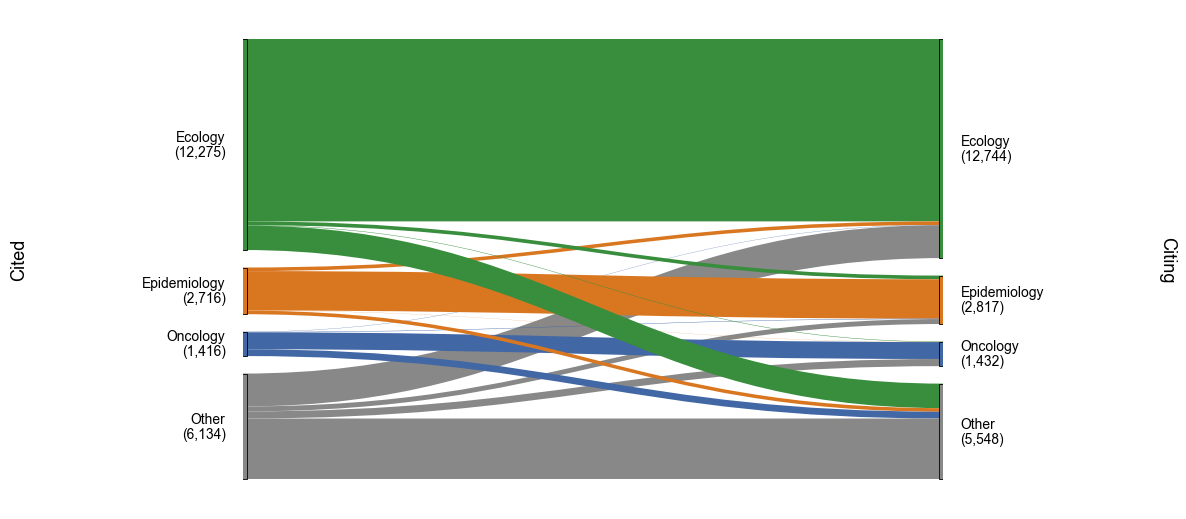

In [12]:

import numpy as np
import matplotlib.pyplot as plt

from matplotlib.path import Path
from matplotlib.patches import PathPatch, Rectangle

# ============================================================
# CITATION CROSS-TALK: SANKEY WITH ALL 16 FLOW LABELS
# ============================================================

# -------------------------------------------------------------------
# 1. PREPARE DATA
# -------------------------------------------------------------------

from matplotlib import font_manager

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 11,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "pdf.fonttype": 42,
})

order = ["ecology", "epidemiology", "oncology", "other"]

field_names = {
    "ecology": "Ecology",
    "epidemiology": "Epidemiology",
    "oncology": "Oncology",
    "other": "Other",
}

# Contrasting subfield colours
#colour_map = {
#    "ecology": "#4E79A7",        # Blue
#    "epidemiology": "#F28E2B",   # Orange
#    "oncology": "#E15759",       # Red
#    "other": "#76B7B2",          # Teal
#}

# Rows = citing subfield; columns = cited subfield
counts = citation_matrix.loc[order, order].fillna(0)

row_totals = counts.sum(axis=1)
col_totals = counts.sum(axis=0)

# Scale ribbon heights to fit the diagram
gap = 0.035
total_citations = row_totals.sum()

scale = (
    0.88 - gap * (len(order) - 1)
) / total_citations


# -------------------------------------------------------------------
# 2. CALCULATE SUBFIELD NODE POSITIONS
# -------------------------------------------------------------------

def calculate_blocks(totals):

    positions = {}
    top = 0.94

    for field in order:

        height = float(totals[field]) * scale

        positions[field] = (
            top - height,
            top,
        )

        top -= height + gap

    return positions


# LEFT = cited subfields
# RIGHT = citing subfields
left_blocks = calculate_blocks(col_totals)
right_blocks = calculate_blocks(row_totals)


# -------------------------------------------------------------------
# 3. CALCULATE POSITIONS OF INDIVIDUAL RIBBONS
# -------------------------------------------------------------------

left_slots = {}
right_slots = {}

# LEFT: ribbons leave the cited subfields
for target in order:

    bottom, top = left_blocks[target]
    cursor = top

    for source in order:

        height = float(
            counts.loc[source, target]
        ) * scale

        left_slots[(source, target)] = (
            cursor - height,
            cursor,
        )

        cursor -= height


# RIGHT: ribbons enter the citing subfields
for source in order:

    bottom, top = right_blocks[source]
    cursor = top

    for target in order:

        height = float(
            counts.loc[source, target]
        ) * scale

        right_slots[(source, target)] = (
            cursor - height,
            cursor,
        )

        cursor -= height


# -------------------------------------------------------------------
# 4. DRAW SANKEY RIBBONS
# -------------------------------------------------------------------

#fig, ax = plt.subplots(figsize=(17, 10))
fig, ax = plt.subplots(figsize=(7, 5))

x_left = 0
x_right = 1

flows = []

for source in order:
    for target in order:

        if counts.loc[source, target] > 0:
            flows.append((source, target))


# Draw ribbons from the top-left subfields first.
# Ribbons from bottom-left subfields are drawn last,
# so they appear on top wherever ribbons overlap.

# -------------------------------------------------------------------
# Draw the citation ribbons
# -------------------------------------------------------------------

for source, target in flows:

    l_bottom, l_top = left_slots[(source, target)]
    r_bottom, r_top = right_slots[(source, target)]

    dx = (x_right - x_left) * 0.45

    vertices = [
        (x_left, l_top),
        (x_left + dx, l_top),
        (x_right - dx, r_top),
        (x_right, r_top),
        (x_right, r_bottom),
        (x_right - dx, r_bottom),
        (x_left + dx, l_bottom),
        (x_left, l_bottom),
        (x_left, l_top),
    ]

    codes = [
        Path.MOVETO,
        Path.CURVE4,
        Path.CURVE4,
        Path.CURVE4,
        Path.LINETO,
        Path.CURVE4,
        Path.CURVE4,
        Path.CURVE4,
        Path.CLOSEPOLY,
    ]

    ax.add_patch(
        PathPatch(
            Path(vertices, codes),
            facecolor=colour_map[target],
            edgecolor="none",
            zorder=1,
        )
    )


# -------------------------------------------------------------------
# 5. DRAW SUBFIELD NODES AND LABELS
# -------------------------------------------------------------------

for field in order:

    for x, blocks in [
        (x_left, left_blocks),
        (x_right, right_blocks),
    ]:

        bottom, top = blocks[field]

        ax.add_patch(
            Rectangle(
                (x - 0.006, bottom),
                0.012,
                top - bottom,
                facecolor=colour_map[field],
                edgecolor="black",
                linewidth=0.6,
                zorder=3,
            )
        )

        if x == x_left:

            label_x = x - 0.025
            alignment = "right"

            # Total citations received by this subfield
            total = int(col_totals[field])

        else:

            label_x = x + 0.025
            alignment = "left"

            # Total citations made by this subfield
            total = int(row_totals[field])

        ax.text(
            label_x,
            (bottom + top) / 2,
            f"{field_names[field]}\n({total:,})",
            ha=alignment,
            va="center",
            fontsize=10,
            linespacing=1.1,
            zorder=4,
            clip_on=False,
        )


# -------------------------------------------------------------------
# 6. LABEL ALL 16 CITATION FLOWS
# -------------------------------------------------------------------

# The labels are grouped by citing subfield.
# Each value shows the citation count and the percentage
# of all citations made by that citing subfield.

for i, source in enumerate(order):

    x = 0.05 + i * 0.25

    """
    ax.text(
        x,
        -0.05,
        field_names[source] + " cites:",
        transform=ax.transAxes,
        fontsize=11,
        fontweight="bold",
        va="top",
        color=colour_map[source],
    )
    """

    for j, target in enumerate(order):

        count = int(
            counts.loc[source, target]
        )

        if row_totals[source] > 0:

            percentage = (
                100 * count / row_totals[source]
            )

        else:

            percentage = 0

        """
        ax.text(
            x,
            -0.10 - j * 0.045,
            f"{field_names[target]}: "
            f"{count:,} ({percentage:.1f}%)",
            transform=ax.transAxes,
            fontsize=9.5,
            va="top",
        )
        """

# -------------------------------------------------------------------
# 7. FORMAT AND EXPORT
# -------------------------------------------------------------------

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
#ax.set_aspect("equal", adjustable="box")
ax.set_aspect("auto")
ax.axis("off")

# Add vertical labels on either side of the Sankey
# Add vertical labels on either side of the Sankey
# -------------------------------------------------------------------
# Vertical labels on either side of the Sankey
# -------------------------------------------------------------------

ax.text(
    -0.32,
    0.5,
    "Cited",
    rotation=90,
    ha="center",
    va="center",
    fontsize=plt.rcParams["axes.labelsize"],
    clip_on=False,
)

ax.text(
    1.32,
    0.5,
    "Citing",
    rotation=270,
    ha="center",
    va="center",
    fontsize=plt.rcParams["axes.labelsize"],
    clip_on=False,
)

"""
fig.subplots_adjust(
    left=0.03,
    right=0.97,
    top=0.94,
    bottom=0.30,
)
"""

fig.subplots_adjust(
    left=0,
    right=1,
    top=1,
    bottom=0,
)

fig.savefig(
    CITATION_OUTPUT_DIR /
    "citation_sankey_cited_to_citing.pdf",
    bbox_inches="tight",
    dpi=300,
)

plt.show()


### (b) Percentages of within-subfield citatinons (citations made)

/var/folders/5y/43d710vn2tv47s8slv7d7c7r0000gn/T/ipykernel_72721/2552148029.py:100: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


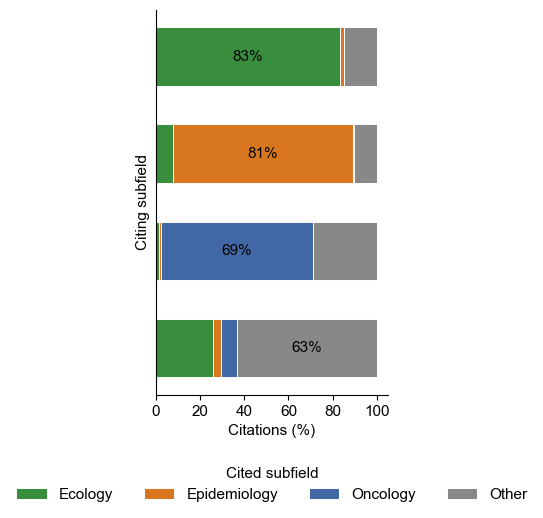

In [13]:
# ============================================================
# PLOT: CITATION FRACTIONS - STACKED HORIZONTAL BAR CHART
# ============================================================

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 11,
    "axes.labelsize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "pdf.fonttype": 42,
})

def plot_stacked_citation_bars(citation_matrix):

    fig, ax = plt.subplots(figsize=(3, 5))

    # Convert citation counts to percentages for each citing subfield
    fractions = citation_matrix.loc[FIELDS, FIELDS].div(
        citation_matrix.loc[FIELDS, FIELDS].sum(axis=1),
        axis=0
    ) * 100

    # Plot stacked horizontal bars
    for i, field in enumerate(FIELDS):

        left = 0

        for cited_field in FIELDS:

            percentage = fractions.loc[field, cited_field]

            ax.barh(
                i,
                percentage,
                left=left,
                height=0.6,
                color=colour_map[cited_field],
                edgecolor="white",
                linewidth=0.7,
                label=cited_field.capitalize() if i == 0 else None
            )

            # Add percentage label for within-subfield citations
            if field == cited_field:

                ax.text(
                    left + percentage / 2,
                    i,
                    f"{percentage:.0f}%",
                    ha="center",
                    va="center",
                    color="black",
                    #fontsize=12,
                    #fontweight="bold"
                )

            left += percentage

    # ---------------------------------------------
    # Format axes
    # ---------------------------------------------

    #ax.set_yticks(range(len(FIELDS)))
    #ax.set_yticklabels([f.capitalize() for f in FIELDS])

    # Ecology at the top
    ax.invert_yaxis()

    ax.set_yticks([])
    ax.set_ylabel("")   

    #ax.set_xlim(0, 100)
    ax.set_xticks(range(0, 101, 20))

    ax.set_xlabel("Citations (%)")
    ax.set_ylabel("Citing subfield")

    # Remove top and right borders
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # ---------------------------------------------
    # Legend
    # ---------------------------------------------

    ax.legend(
        title="Cited subfield",
        loc="upper center",
        bbox_to_anchor=(0.5, -0.15),
        ncol=4,
        frameon=False
    )

    # ---------------------------------------------
    # Save figure
    # ---------------------------------------------

    plt.tight_layout()

    fig.savefig(
        CITATION_OUTPUT_DIR / "stacked_citation_fractions.pdf",
        bbox_inches="tight"
    )

    plt.show()


plot_stacked_citation_bars(citation_matrix)

### (b) Percentages of within-subfield citatinons (citations received)


CITATION PERCENTAGES RECEIVED BY SUBFIELD
Rows = Citing subfield
Columns = Cited subfield

cited_field   ecology  epidemiology  oncology  other
citing_field                                        
ecology         86.43          7.66      0.99  31.19
epidemiology     1.75         84.35      1.62   4.70
oncology         0.20          0.29     69.49   6.77
other           11.62          7.70     27.90  57.35

Each column sums to 100%.



/var/folders/5y/43d710vn2tv47s8slv7d7c7r0000gn/T/ipykernel_72721/3237372893.py:94: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


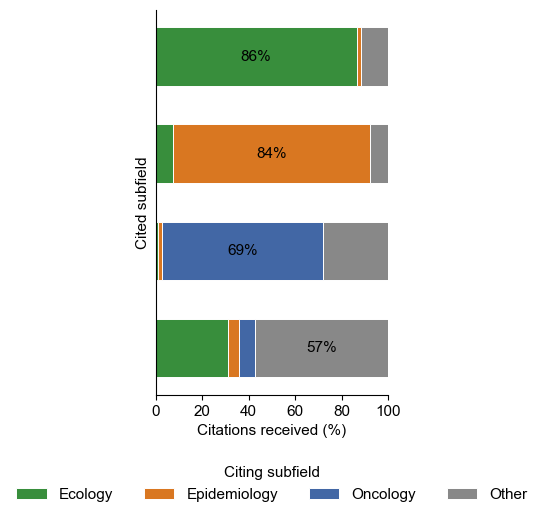

In [14]:

def plot_stacked_citation_bars(citation_matrix):

    fig, ax = plt.subplots(figsize=(3, 5))

    # Convert citation counts to percentages for each CITED subfield
    fractions = citation_matrix.loc[FIELDS, FIELDS].div(
        citation_matrix.loc[FIELDS, FIELDS].sum(axis=0),
        axis=1
    ) * 100

    # ---------------------------------------------
    # Print all percentages to terminal
    # ---------------------------------------------

    print("\n============================================")
    print("CITATION PERCENTAGES RECEIVED BY SUBFIELD")
    print("============================================")
    print("Rows = Citing subfield")
    print("Columns = Cited subfield\n")

    print(fractions.to_string(float_format=lambda x: f"{x:.2f}"))

    print("\nEach column sums to 100%.\n")

    # Each bar now represents a CITED subfield
    for i, field in enumerate(FIELDS):

        left = 0

        # Each segment represents the CITING subfield
        for citing_field in FIELDS:

            percentage = fractions.loc[citing_field, field]

            ax.barh(
                i,
                percentage,
                left=left,
                height=0.6,
                color=colour_map[citing_field],
                edgecolor="white",
                linewidth=0.7,
                label=citing_field.capitalize() if i == 0 else None
            )

            # Add percentage label for within-subfield citations
            if field == citing_field:

                ax.text(
                    left + percentage / 2,
                    i,
                    f"{percentage:.0f}%",
                    ha="center",
                    va="center",
                    color="black"
                )

            left += percentage

    # ---------------------------------------------
    # Format axes
    # ---------------------------------------------

    ax.invert_yaxis()

    ax.set_yticks([])
    ax.set_ylabel("")

    ax.set_xlim(0, 100)
    ax.set_xticks(range(0, 101, 20))

    ax.set_xlabel("Citations received (%)")
    ax.set_ylabel("Cited subfield")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # ---------------------------------------------
    # Legend
    # ---------------------------------------------

    ax.legend(
        title="Citing subfield",
        loc="upper center",
        bbox_to_anchor=(0.5, -0.15),
        ncol=4,
        frameon=False
    )

    # ---------------------------------------------
    # Save figure
    # ---------------------------------------------

    plt.tight_layout()

    fig.savefig(
        CITATION_OUTPUT_DIR / "stacked_citation_fractions_received.pdf",
        bbox_inches="tight"
    )

    plt.show()


plot_stacked_citation_bars(citation_matrix)


### Permutation test (citations made)

In [64]:
# ============================================================
# PERMUTATION TEST: WITHIN-SUBFIELD CITATION
# ============================================================

# Test whether articles cite their own subfield more frequently than would be expected based on the number of 
# articles in each subfield.

# Subfield labels are randomly shuffled between articles published in the same year, while the citation links themselves 
# remain unchanged, thus preserving the number of articles in each subfield within each year.

# -------------------------------------------------------------------
# 1. CALCULATE OBSERVED WITHIN-SUBFIELD CITATION PERCENTAGES
# -------------------------------------------------------------------

# Calculate the percentage of citations made by each subfield
# that are directed towards the same subfield
def calculate_within_field_percentages(citation_df):

    percentages = {}

    for field in FIELDS:

        # Select all citations made by this subfield
        subset = citation_df[
            citation_df["citing_field"] == field
        ]

        # Count all citations made by this subfield
        total_citations = len(subset)

        # Count citations directed towards the same subfield
        within_field_citations = (
            subset["cited_field"] == field
        ).sum()

        # Calculate the percentage directed towards the same subfield
        percentages[field] = (
            within_field_citations / total_citations
        ) * 100

    return percentages


# Calculate the observed percentages using the original citation data
observed_within = calculate_within_field_percentages(df)

print("Observed within-subfield citation percentages (made):")

for field in FIELDS:
    print(f"{field}: {observed_within[field]:.1f}%")


# -------------------------------------------------------------------
# 2. SHUFFLE SUBFIELD LABELS WITHIN PUBLICATION YEARS
# -------------------------------------------------------------------

# Randomly shuffle the subfield labels between articles publised in the same year.
# The number of articles belonging to each subfield in each year remains unchanged.
def shuffle_fields_within_year(ut_lookup, rng):

    shuffled_lookup = {}

    # Group article UTs by publication year
    articles_by_year = defaultdict(list)

    for ut, info in ut_lookup.items():
        articles_by_year[info["year"]].append(ut)

    # Shuffle the existing subfield labels separately within each year
    for year, uts in articles_by_year.items():

        
        fields = []

        # Collect the original subfield labels of articles published in this year
        for ut in uts:
            fields.append(
                ut_lookup[ut]["field"]
            )

        # Randomly rearrange the labels while keeping the number of articles in each subfield the same
        shuffled_fields = rng.permutation(fields) #rng is random number generartor

        # Assign the suffled labels back to the articles from this year
        for i in range(len(uts)):
            ut = uts[i]
            shuffled_field = shuffled_fields[i]

            shuffled_lookup[ut] = shuffled_field

    return shuffled_lookup


# -------------------------------------------------------------------
# 3. RECALCULATE WITHIN-SUBFIELD CITATION AFTER SHUFFLING
# -------------------------------------------------------------------

# Calculate the within-subfield citation percentages after assigning the shuffled subfield labels
def calculate_shuffled_within_percentages(
    citation_df,
    shuffled_lookup,
):

    # Copy the original citation data
    shuffled_df = citation_df.copy()

    # Replace the original subfield labels with the shuffled labels
    shuffled_df["citing_field"] = (
        shuffled_df["citing_ut"].map(shuffled_lookup)
    )

    shuffled_df["cited_field"] = (
        shuffled_df["cited_ut"].map(shuffled_lookup)
    )

    # Calculate the within-subfield citation percentages
    return calculate_within_field_percentages(
        shuffled_df
    )


# -------------------------------------------------------------------
# 4. RUN THE PERMUTATION TEST
# -------------------------------------------------------------------

N_PERMUTATIONS = 1000 # number of times we shuffle the labels
RANDOM_SEED = 42 # for reproducibility 

rng = np.random.default_rng(RANDOM_SEED)


# Store the shuffled subfield assigned to every article during each permutation
shuffled_article_labels = {}

for ut in ut_lookup:
    shuffled_article_labels[ut] = []


# Store the within-subfield citation percentage from every permutation
permutation_results = {}

for field in FIELDS:
    permutation_results[field] = []


for _ in range(N_PERMUTATIONS):

    # Randomly shuffle subfield labels within each publication year
    shuffled_lookup = shuffle_fields_within_year(
        ut_lookup,
        rng,
    )

    # Store the shuffled label assigned to each article in this permutation
    for ut in ut_lookup:
        shuffled_article_labels[ut].append(
            shuffled_lookup[ut]
        )

    # Recalculate within-subfield citation percentages for this permutation
    shuffled_percentages = (
        calculate_shuffled_within_percentages(
            df,
            shuffled_lookup,
        )
    )

    # Store the result for each subfield
    for field in FIELDS:
        permutation_results[field].append(
            shuffled_percentages[field]
        )


# -------------------------------------------------------------------
# 5. SUMMARISE THE PERMUTATION RESULTS
# -------------------------------------------------------------------

summary_rows = []

for field in FIELDS:

    # Get the 1000 within-subfield citation percentages obtained from the shuffled labels
    null_values = np.array(
        permutation_results[field]
    )

    # The actual observed within-subfield citation percentage
    observed = observed_within[field]

    # Calculate the mean within-subfield citation percentage across the 1000 permutations
    null_mean = null_values.mean()

    # Calculate the 95% interval of the permutation distribution, i.e., 95% of out results are between 
    # the 2.5th and 97.5th percentile
    null_lower = np.percentile(null_values, 2.5)
    null_upper = np.percentile(null_values, 97.5)

    # Q: Are within-subfield citations greater than would be expected if subfield labels were randomly distributed?
    # Is the observed value unusually high? Let's see if the shuffling ever produces higher percentages.
    # Calculate the one-sided permutation p-value as the proportion of shuffled values that
    # are at least as large as the observed value
    # The plus one includes the observed as a permutation too.
    p_value = (
        np.sum(null_values >= observed) + 1
    ) / (
        N_PERMUTATIONS + 1
    )

    summary_rows.append({
        "field": field,
        "observed_percent": observed,
        "null_mean_percent": null_mean,
        "null_2.5_percent": null_lower,
        "null_97.5_percent": null_upper,
        "p_value": p_value,
    })


permutation_summary = pd.DataFrame(
    summary_rows
)

print("\nPermutation test results:")
display(permutation_summary.round(3))

# -------------------------------------------------------------------
# 6. EXPORT SHUFFLED ARTICLE LABELS
# -------------------------------------------------------------------

# Create one row for each article containing its publication year,
# original subfield, and subfield assigned in each permutation
shuffle_rows = []

for ut, info in ut_lookup.items():

    # Store the publication year, article UT, and original subfield
    row = {
        "Year": info["year"],
        "UT": ut,
        "Original": info["field"],
    }

    # Add the shuffled label from each permutation as a new column
    for i in range(N_PERMUTATIONS):

        shuffled_field = shuffled_article_labels[ut][i]

        row[f"New{i + 1}"] = shuffled_field

    # Add the completed row for this article
    shuffle_rows.append(row)


# Convert to a dataframe and order articles by publication year
shuffle_df = pd.DataFrame(
    shuffle_rows
).sort_values(
    ["Year", "UT"]
)


# Save all original and shuffled labels to Excel
SHUFFLE_OUTPUT_FILE = (
    CITATION_OUTPUT_DIR /
    "permutation_article_labels.xlsx"
)

shuffle_df.to_excel(
    SHUFFLE_OUTPUT_FILE,
    index=False,
)

print(
    f"Permutation article labels saved to: "
    f"{SHUFFLE_OUTPUT_FILE}"
)

Observed within-subfield citation percentages (made):
ecology: 83.2%
epidemiology: 81.3%
oncology: 68.7%
other: 63.4%

Permutation test results:


,field,observed_percent,null_mean_percent,null_2.5_percent,null_97.5_percent,p_value
0,ecology,83.247,61.730,57.789,64.901,0.001
1,epidemiology,81.328,13.667,11.880,16.415,0.001
2,oncology,68.715,3.740,2.338,5.453,0.001
3,other,63.410,25.544,22.499,29.359,0.001


Permutation article labels saved to: outputs/citation_field_overlap_outputs/permutation_article_labels.xlsx


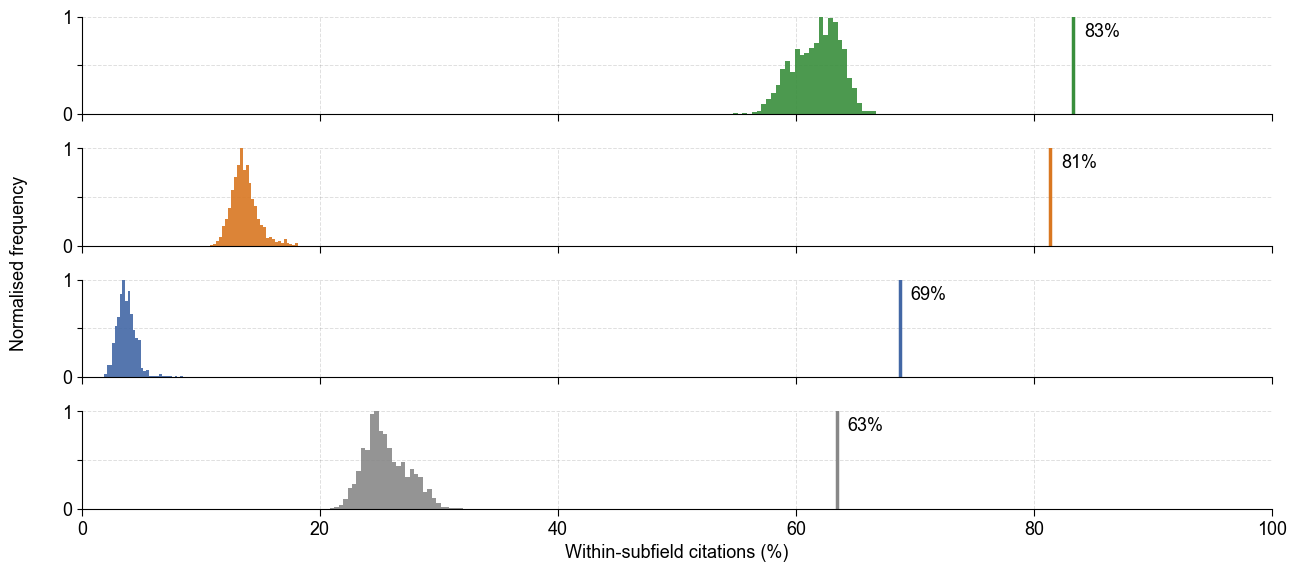

In [65]:

# ============================================================
# PLOT: PERMUTATION DISTRIBUTIONS - FOUR STACKED PANELS
# ============================================================
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 11,
    "axes.labelsize": 13,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 11,
    "pdf.fonttype": 42,
})

def plot_permutation_results(
    permutation_results,
    observed_within,
):

    # Create four vertically stacked panels
    fig, axes = plt.subplots(
        4, 1,
        figsize=(14, 6),
        sharex=True
    )

    # Plot each subfield separately
    for i, field in enumerate(FIELDS):

        ax = axes[i]

        null_values = permutation_results[field]
        observed = observed_within[field]

        # ---------------------------------------------
        # Permutation distribution
        # ---------------------------------------------

        counts, bin_edges = np.histogram(null_values, bins=30)

        ax.hist(
            null_values,
            bins=bin_edges,
            weights=np.ones(len(null_values)) / counts.max(),
            color=colour_map[field],
            alpha=0.9
        )

        # ---------------------------------------------
        # Observed value
        # ---------------------------------------------

        ax.axvline(
            observed,
            color=colour_map[field],
            linewidth=2.5,
            linestyle="-"
        )

        # Add observed percentage beside the line
        ax.annotate(
            f"{observed:.0f}%",
            xy=(observed, 0.85),
            xycoords=("data", "axes fraction"),
            xytext=(8, 0),
            textcoords="offset points",
            ha="left",
            va="center",
            fontsize=13,
            color="black",
            #fontweight="bold"
        )

        """
        # ---------------------------------------------
        # Subfield label on the left
        # ---------------------------------------------

        ax.set_ylabel(
            field.capitalize(),
            rotation=0,
            ha="right",
            va="center",
            labelpad=20,
            fontsize=12
        )
        """


        # ---------------------------------------------
        # Format axes
        # ---------------------------------------------

        # X-axis: within-subfield citation percentage
        ax.set_xlim(0, 100)

        # Y-axis: number of permutations
        ax.set_ylim(0, 1)
        ax.set_yticks([0, 0.5, 1])
        ax.set_yticklabels(["0", "", "1"])
        ax.tick_params(
            axis="y",
            left=True,
            labelleft=True,
            labelsize=13
        )

        # Remove top and right borders
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        # Keep left and bottom axes black
        ax.spines["left"].set_visible(True)
        ax.spines["left"].set_color("black")
        ax.spines["left"].set_linewidth(0.8)

        ax.spines["bottom"].set_visible(True)
        ax.spines["bottom"].set_color("black")
        ax.spines["bottom"].set_linewidth(0.8)

        # ---------------------------------------------
        # X-axis ticks on ALL panels
        # ---------------------------------------------

        ax.set_xticks(range(0, 101, 20))

        ax.tick_params(
            axis="x",
            which="major",
            bottom=True,
            labelbottom=(i == len(FIELDS) - 1),
            length=5,
            width=0.8,
            labelsize=13
        )

        # ---------------------------------------------
        # Faint horizontal grid lines
        # ---------------------------------------------

        ax.set_axisbelow(True)

        ax.yaxis.grid(
            True,
            linestyle="--",
            color="grey",
            alpha=0.25,
            linewidth=0.7
        )
        # ---------------------------------------------
        # Faint vertical grid lines
        # ---------------------------------------------

        ax.set_axisbelow(True)

        ax.xaxis.grid(
            True,
            linestyle="--",
            color="grey",
            alpha=0.25,
            linewidth=0.7
        )

    # ---------------------------------------------
    # Shared axis label
    # ---------------------------------------------

    axes[-1].set_xlabel(
        "Within-subfield citations (%)",
        fontsize=13,
    )

    fig.text(
        0.055,
        0.54,
        "Normalised frequency",
        rotation=90,
        fontsize=13,
        ha="center",
        va="center"
    )

    # ---------------------------------------------
    # Layout and save
    # ---------------------------------------------

    plt.subplots_adjust(
        left=0.10,
        right=0.95,
        top=0.95,
        bottom=0.13,
        hspace=0.35
    )

    fig.savefig(
        CITATION_OUTPUT_DIR /
        "permutation_within_subfield_citations.pdf",
        bbox_inches="tight"
    )

    plt.show()


plot_permutation_results(
    permutation_results,
    observed_within,
)


### Permutation test (citations received)

In [17]:
# ============================================================
# PERMUTATION TEST: WITHIN-SUBFIELD CITATION
# ============================================================

# Test whether articles cite their own subfield more frequently than would be expected based on the number of 
# articles in each subfield.

# Subfield labels are randomly shuffled between articles published in the same year, while the citation links themselves 
# remain unchanged, thus preserving the number of articles in each subfield within each year.

# -------------------------------------------------------------------
# 1. CALCULATE OBSERVED WITHIN-SUBFIELD CITATION PERCENTAGES
# -------------------------------------------------------------------


# Calculate the percentage of citations received by each subfield
# that originate from the same subfield
def calculate_within_field_percentages(citation_df):

    percentages = {}

    for field in FIELDS:

        # Select all citations received by this subfield
        subset = citation_df[
            citation_df["cited_field"] == field
        ]

        # Count all citations received by this subfield
        total_citations = len(subset)

        # Count citations originating from the same subfield
        within_field_citations = (
            subset["citing_field"] == field
        ).sum()

        # Calculate the percentage originating from the same subfield
        percentages[field] = (
            within_field_citations / total_citations
        ) * 100 if total_citations > 0 else np.nan

    return percentages


# Calculate the observed percentages using the original citation data
observed_within = calculate_within_field_percentages(df)

print("Observed within-subfield citation percentages:")

for field in FIELDS:
    print(f"{field}: {observed_within[field]:.1f}%")


# -------------------------------------------------------------------
# 2. SHUFFLE SUBFIELD LABELS WITHIN PUBLICATION YEARS
# -------------------------------------------------------------------

# Randomly shuffle the subfield labels between articles publised in the same year.
# The number of articles belonging to each subfield in each year remains unchanged.
def shuffle_fields_within_year(ut_lookup, rng):

    shuffled_lookup = {}

    # Group article UTs by publication year
    articles_by_year = defaultdict(list)

    for ut, info in ut_lookup.items():
        articles_by_year[info["year"]].append(ut)

    # Shuffle the existing subfield labels separately within each year
    for year, uts in articles_by_year.items():

        
        fields = []

        # Collect the original subfield labels of articles published in this year
        for ut in uts:
            fields.append(
                ut_lookup[ut]["field"]
            )

        # Randomly rearrange the labels while keeping the number of articles in each subfield the same
        shuffled_fields = rng.permutation(fields) #rng is random number generartor

        # Assign the suffled labels back to the articles from this year
        for i in range(len(uts)):
            ut = uts[i]
            shuffled_field = shuffled_fields[i]

            shuffled_lookup[ut] = shuffled_field

    return shuffled_lookup


# -------------------------------------------------------------------
# 3. RECALCULATE WITHIN-SUBFIELD CITATION AFTER SHUFFLING
# -------------------------------------------------------------------

# Calculate the within-subfield citation percentages after assigning the shuffled subfield labels
def calculate_shuffled_within_percentages(
    citation_df,
    shuffled_lookup,
):

    # Copy the original citation data
    shuffled_df = citation_df.copy()

    # Replace the original subfield labels with the shuffled labels
    shuffled_df["citing_field"] = (
        shuffled_df["citing_ut"].map(shuffled_lookup)
    )

    shuffled_df["cited_field"] = (
        shuffled_df["cited_ut"].map(shuffled_lookup)
    )

    # Calculate the within-subfield citation percentages
    return calculate_within_field_percentages(
        shuffled_df
    )


# -------------------------------------------------------------------
# 4. RUN THE PERMUTATION TEST
# -------------------------------------------------------------------

N_PERMUTATIONS = 1000 # number of times we shuffle the labels
RANDOM_SEED = 42 # for reproducibility 

rng = np.random.default_rng(RANDOM_SEED)


# Store the shuffled subfield assigned to every article during each permutation
shuffled_article_labels = {}

for ut in ut_lookup:
    shuffled_article_labels[ut] = []


# Store the within-subfield citation percentage from every permutation
permutation_results = {}

for field in FIELDS:
    permutation_results[field] = []


for _ in range(N_PERMUTATIONS):

    # Randomly shuffle subfield labels within each publication year
    shuffled_lookup = shuffle_fields_within_year(
        ut_lookup,
        rng,
    )

    # Store the shuffled label assigned to each article in this permutation
    for ut in ut_lookup:
        shuffled_article_labels[ut].append(
            shuffled_lookup[ut]
        )

    # Recalculate within-subfield citation percentages for this permutation
    shuffled_percentages = (
        calculate_shuffled_within_percentages(
            df,
            shuffled_lookup,
        )
    )

    # Store the result for each subfield
    for field in FIELDS:
        permutation_results[field].append(
            shuffled_percentages[field]
        )


# -------------------------------------------------------------------
# 5. SUMMARISE THE PERMUTATION RESULTS
# -------------------------------------------------------------------

summary_rows = []

for field in FIELDS:

    # Get the 1000 within-subfield citation percentages obtained from the shuffled labels
    null_values = np.array(
        permutation_results[field]
    )

    # The actual observed within-subfield citation percentage
    observed = observed_within[field]

    # Calculate the mean within-subfield citation percentage across the 1000 permutations
    null_mean = null_values.mean()

    # Calculate the 95% interval of the permutation distribution, i.e., 95% of out results are between 
    # the 2.5th and 97.5th percentile
    null_lower = np.percentile(null_values, 2.5)
    null_upper = np.percentile(null_values, 97.5)

    # Q: Are within-subfield citations greater than would be expected if subfield labels were randomly distributed?
    # Is the observed value unusually high? Let's see if the shuffling ever produces higher percentages.
    # Calculate the one-sided permutation p-value as the proportion of shuffled values that
    # are at least as large as the observed value
    # The plus one includes the observed as a permutation too.
    p_value = (
        np.sum(null_values >= observed) + 1
    ) / (
        N_PERMUTATIONS + 1
    )

    summary_rows.append({
        "field": field,
        "observed_percent": observed,
        "null_mean_percent": null_mean,
        "null_2.5_percent": null_lower,
        "null_97.5_percent": null_upper,
        "p_value": p_value,
    })


permutation_summary = pd.DataFrame(
    summary_rows
)

print("\nPermutation test results:")
display(permutation_summary.round(3))

# -------------------------------------------------------------------
# 6. EXPORT SHUFFLED ARTICLE LABELS
# -------------------------------------------------------------------

# Create one row for each article containing its publication year,
# original subfield, and subfield assigned in each permutation
shuffle_rows = []

for ut, info in ut_lookup.items():

    # Store the publication year, article UT, and original subfield
    row = {
        "Year": info["year"],
        "UT": ut,
        "Original": info["field"],
    }

    # Add the shuffled label from each permutation as a new column
    for i in range(N_PERMUTATIONS):

        shuffled_field = shuffled_article_labels[ut][i]

        row[f"New{i + 1}"] = shuffled_field

    # Add the completed row for this article
    shuffle_rows.append(row)


# Convert to a dataframe and order articles by publication year
shuffle_df = pd.DataFrame(
    shuffle_rows
).sort_values(
    ["Year", "UT"]
)


# Save all original and shuffled labels to Excel
SHUFFLE_OUTPUT_FILE = (
    CITATION_OUTPUT_DIR /
    "permutation_article_labels.xlsx"
)

shuffle_df.to_excel(
    SHUFFLE_OUTPUT_FILE,
    index=False,
)

print(
    f"Permutation article labels saved to: "
    f"{SHUFFLE_OUTPUT_FILE}"
)

Observed within-subfield citation percentages:
ecology: 86.4%
epidemiology: 84.4%
oncology: 69.5%
other: 57.4%

Permutation test results:


,field,observed_percent,null_mean_percent,null_2.5_percent,null_97.5_percent,p_value
0,ecology,86.428,49.899,48.198,51.398,0.001
1,epidemiology,84.352,22.291,20.228,24.465,0.001
2,oncology,69.492,5.605,3.830,7.555,0.001
3,other,57.352,27.958,26.298,29.613,0.001


Permutation article labels saved to: outputs/citation_field_overlap_outputs/permutation_article_labels.xlsx


/var/folders/5y/43d710vn2tv47s8slv7d7c7r0000gn/T/ipykernel_72721/2614671552.py:98: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(["0", "", "1"])
/var/folders/5y/43d710vn2tv47s8slv7d7c7r0000gn/T/ipykernel_72721/2614671552.py:98: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(["0", "", "1"])
/var/folders/5y/43d710vn2tv47s8slv7d7c7r0000gn/T/ipykernel_72721/2614671552.py:98: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(["0", "", "1"])
/var/folders/5y/43d710vn2tv47s8slv7d7c7r0000gn/T/ipykernel_72721/2614671552.py:98: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(["0", "", "1"])


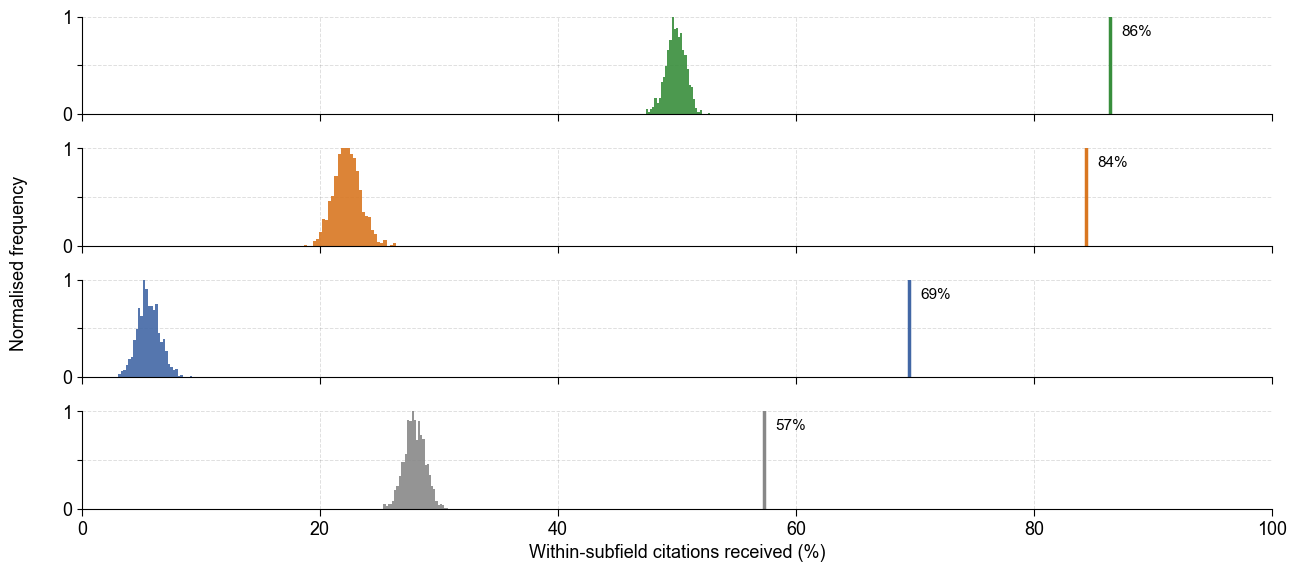

In [18]:

# ============================================================
# PLOT: PERMUTATION DISTRIBUTIONS - FOUR STACKED PANELS
# ============================================================
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 11,
    "axes.labelsize": 13,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 11,
    "pdf.fonttype": 42,
})

def plot_permutation_results(
    permutation_results,
    observed_within,
):

    # Create four vertically stacked panels
    fig, axes = plt.subplots(
        4, 1,
        figsize=(14, 6),
        sharex=True
    )

    # Plot each subfield separately
    for i, field in enumerate(FIELDS):

        ax = axes[i]

        null_values = permutation_results[field]
        observed = observed_within[field]

        # ---------------------------------------------
        # Permutation distribution
        # ---------------------------------------------

        counts, bin_edges = np.histogram(null_values, bins=30)

        ax.hist(
            null_values,
            bins=bin_edges,
            weights=np.ones(len(null_values)) / counts.max(),
            color=colour_map[field],
            alpha=0.9
        )

        # ---------------------------------------------
        # Observed value
        # ---------------------------------------------

        ax.axvline(
            observed,
            color=colour_map[field],
            linewidth=2.5,
            linestyle="-"
        )

        # Add observed percentage beside the line
        ax.annotate(
            f"{observed:.0f}%",
            xy=(observed, 0.85),
            xycoords=("data", "axes fraction"),
            xytext=(8, 0),
            textcoords="offset points",
            ha="left",
            va="center",
            fontsize=11,
            color="black",
            #fontweight="bold"
        )

        """
        # ---------------------------------------------
        # Subfield label on the left
        # ---------------------------------------------

        ax.set_ylabel(
            field.capitalize(),
            rotation=0,
            ha="right",
            va="center",
            labelpad=20,
            fontsize=12
        )
        """


        # ---------------------------------------------
        # Format axes
        # ---------------------------------------------

        # X-axis: within-subfield citation percentage
        ax.set_xlim(0, 100)

        # Y-axis: number of permutations
        ax.set_ylim(0, 1)
        ax.set_yticklabels(["0", "", "1"])

        ax.tick_params(
            axis="y",
            left=True,
            labelleft=True,
            labelsize=13
        )

        # Remove top and right borders
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        # Keep left and bottom axes black
        ax.spines["left"].set_visible(True)
        ax.spines["left"].set_color("black")
        ax.spines["left"].set_linewidth(0.8)

        ax.spines["bottom"].set_visible(True)
        ax.spines["bottom"].set_color("black")
        ax.spines["bottom"].set_linewidth(0.8)


        # ---------------------------------------------
        # X-axis ticks on ALL panels
        # ---------------------------------------------

        ax.set_xticks(range(0, 101, 20))

        ax.tick_params(
            axis="x",
            which="major",
            bottom=True,
            labelbottom=(i == len(FIELDS) - 1),
            length=5,
            width=0.8,
            labelsize=13
        )

        # ---------------------------------------------
        # Faint horizontal grid lines
        # ---------------------------------------------

        ax.set_axisbelow(True)

        ax.yaxis.grid(
            True,
            linestyle="--",
            color="grey",
            alpha=0.25,
            linewidth=0.7
        )
        # ---------------------------------------------
        # Faint vertical grid lines
        # ---------------------------------------------

        ax.set_axisbelow(True)

        ax.xaxis.grid(
            True,
            linestyle="--",
            color="grey",
            alpha=0.25,
            linewidth=0.7
        )

    # ---------------------------------------------
    # Shared axis label
    # ---------------------------------------------

    axes[-1].set_xlabel(
        "Within-subfield citations received (%)",
        fontsize=13,
    )

    fig.text(
        0.055,
        0.54,
        "Normalised frequency",
        rotation=90,
        fontsize=13,
        ha="center",
        va="center"
    )

    # ---------------------------------------------
    # Layout and save
    # ---------------------------------------------

    plt.subplots_adjust(
        left=0.10,
        right=0.95,
        top=0.95,
        bottom=0.13,
        hspace=0.35
    )

    fig.savefig(
        CITATION_OUTPUT_DIR /
        "permutation_within_subfield_citations_received.pdf",
        bbox_inches="tight"
    )

    plt.show()


plot_permutation_results(
    permutation_results,
    observed_within,
)


---

# **Result 3** (Figure 4): Cross-subfield overlap in ORCID-identified authors.

This section first evaluates ORCID coverage across the biological subfields to determine the years for which author overlap will be analsyed. It then identifies unique ORCID ID's from the WoS dataset and investigates how many authors contribute to one, two, or three of the biological subfields (ecology, epidemiology, other). 

In [19]:
# ============================================================
# ORCID HELPER FUNCTIONS
# ============================================================
 
# Extract an ORCID ID from authors in the dataset
def extract_orcid(author):
    match = re.search(
        r"\[(\d{4}-\d{4}-\d{4}-\d{3}[\dX])\]",
        author
    )

    if match:
        return match.group(1)

    return None

# Remove bracketed ORCID information from an author field
def clean_author_name(author):
    author = re.sub(r"\[[^\]]*\]", "", author)
    author = re.sub(r"\s+", " ", author)
    return author.strip()

ORCID coverage results saved to: outputs/orcid_field_overlap_outputs/orcid_coverage_over_time.xlsx


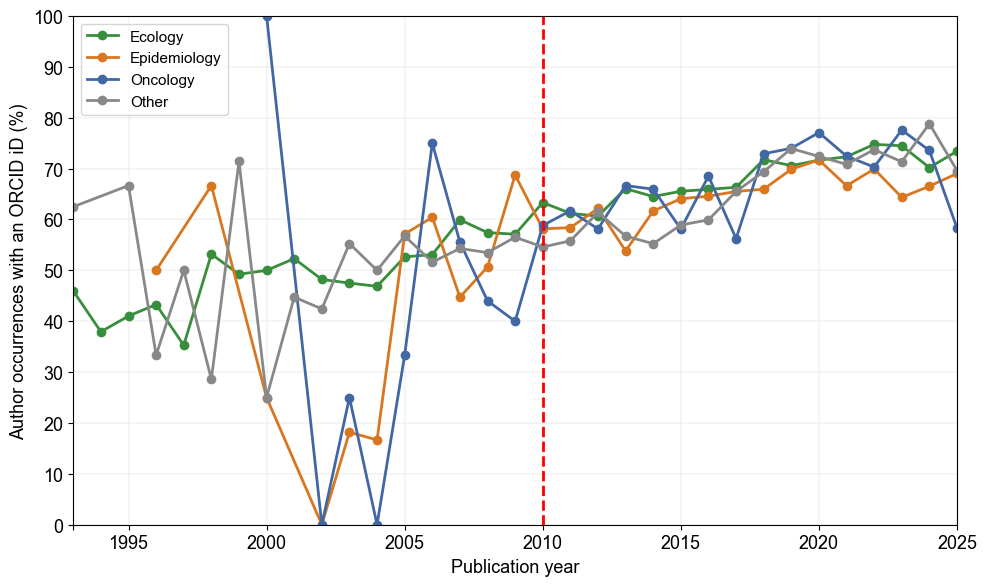

In [20]:
# ============================================================
# ORCID COVERAGE OVER TIME
# ============================================================

# ----------------------------
# 1. Record ORCID coverage for each author occurrence
# ----------------------------

orcid_coverage_rows = []

for record in records:
    category = extract_field(record, "KA")
    year = extract_field(record, "PY")
    ao = extract_field(record, "AO")

    # Skip records missing the required fields
    if category is None or year is None or ao is None:
        continue

    category = category.strip().lower()

    # Keep only the biological subfields
    if category not in FIELDS:
        continue

    # Convert the Year value to an integer
    try:
        year = int(year)
    except ValueError:
        continue

    # Treat each author occurrence of an author on a paper independently (split the authors and then create one row per author)
    authors = [
        author.strip()
        for author in ao.split(";")
        if author.strip() # Ignore any empty entries (e.g., if there are 2 semicolons in a row)
    ]

    for author in authors:
        orcid_coverage_rows.append({
            "category": category,
            "year": year,
            "has_orcid": extract_orcid(author) is not None,
        })

orcid_coverage_df = pd.DataFrame(orcid_coverage_rows)


# ----------------------------
# 2. Calculate ORCID coverage by year and subfield
# ----------------------------

orcid_coverage_by_year = (
    orcid_coverage_df
    .groupby(["category", "year"])
    .agg(
        total_author_occurrences=("has_orcid", "size"),
        author_occurrences_with_orcid=("has_orcid", "sum"),
        orcid_coverage_percent=(
            "has_orcid",
            lambda values: values.mean() * 100
        ),
    )
    .reset_index()
)


# ----------------------------
# 3. Save ORCID coverage results
# ----------------------------

orcid_coverage_excel_path = (
    ORCID_OUTPUT_DIR / "orcid_coverage_over_time.xlsx"
)

orcid_coverage_by_year.to_excel(
    orcid_coverage_excel_path,
    index=False,
)

print(
    f"ORCID coverage results saved to: "
    f"{orcid_coverage_excel_path}"
)


# ----------------------------
# 4. Plot ORCID coverage
# ----------------------------

orcid_coverage_plot = orcid_coverage_by_year.copy()

fig, ax = plt.subplots(figsize=(10, 6))

for category in FIELDS:
    subset = orcid_coverage_plot[
        orcid_coverage_plot["category"] == category
    ]

    ax.plot(
        subset["year"],
        subset["orcid_coverage_percent"],
        marker="o",
        linewidth=2,
        label=category.capitalize(),
        color=colour_map[category],
    )


# ----------------------------
# 5. Format axes
# ----------------------------

years = sorted(orcid_coverage_plot["year"].unique())

# Find the first year from which all subfields remain at or above 50% ORCID coverage
coverage_threshold = 50

first_year_above_threshold = None

for year in years:

    # Select the data from the current year onwards
    later_data = orcid_coverage_plot[
        orcid_coverage_plot["year"] >= year
    ]

    # Assume all years meet the threshold unless one fails the check
    all_years_pass = True

    for later_year in years:

        # Ignore years before the current starting year
        if later_year < year:
            continue

        # Select the ORCID coverage values for this year
        year_data = later_data[
            later_data["year"] == later_year
        ]

        # Check that all subfields have articles and have at least 50% ORCID coverage
        if (
            len(year_data) != len(FIELDS) 
            or
            (year_data["orcid_coverage_percent"] < coverage_threshold).any()
        ):
            all_years_pass = False
            break

    # If every subsequent year passes, use this as the start of the analysis period
    if all_years_pass:
        first_year_above_threshold = year
        break

ax.set_xticks([1993] + list(range(1995, 2026, 5)))
ax.set_xticklabels([""] + list(range(1995, 2026, 5)))

ax.set_xlim(1993, 2025)

ax.set_yticks(range(0, 101, 10))
ax.set_xlabel("Publication year")
ax.set_ylabel("Author occurrences with an ORCID iD (%)")
ax.set_ylim(0, 100)


# Add horizontal and vertical grid lines at each tick
ax.grid(
    True,
    which="major",
    axis="both",
    color="lightgrey",
    linestyle="-",
    linewidth=0.3,
)

# Add red line to show when orcid id coverage is above 50% annually for each subfield
ax.axvline(
    x=first_year_above_threshold,
    color="red",
    linestyle="--",
    linewidth=2,
)

ax.legend(loc="upper left")


# ----------------------------
# 6. Save figure
# ----------------------------

plt.tight_layout()
plt.savefig(ORCID_OUTPUT_DIR / "orcid_coverage_over_time.pdf")
plt.show()

### Results when ORCID coverage is over 50% annually for each subfield

In [21]:
# ============================================================
# ORCID SUBFIELD OVERLAPS - COLLECTION OF DATA
# ============================================================

# -------------------------------------------------------------------
# Collect ORCID-identified authors for each biological subfield into dictionaries
# -------------------------------------------------------------------

# Store the biological subfields, author names, and publication counts associated with each unique ORCID ID

orcid_to_categories = defaultdict(set)
orcid_to_counts = defaultdict(lambda: defaultdict(int))
orcid_to_names = defaultdict(set)

# Track the number of records and author occurences processed for each biological subfield

records_read = defaultdict(int)
authors_read = defaultdict(int)
authors_with_orcid_read = defaultdict(int)


records = extract_records(INPUT_FILE)

# Use the starting year calculated from annual ORCID coverage
if first_year_above_threshold is None:
    raise ValueError(
        "No starting year satisfies the ORCID coverage threshold."
    )

print(
    f"ORCID overlap analysis starting from "
    f"{first_year_above_threshold} "
    f"(coverage threshold: {coverage_threshold}%)"
)

for record in records:

    # Get publication year
    year = extract_field(record, "PY")

    if year is None:
        continue

    try:
        year = int(year)
    except ValueError:
        continue

    # Exclude articles before the automatically calculated year
    if year < first_year_above_threshold:
        continue


    # Read category from KA field
    category = extract_field(record, "KA")
    year = extract_field(record, "PY")

    # Skip articles without a KA field
    if category is None or year is None:
        continue

    category = category.strip().lower()

    # Skip articles not in FIELDS category
    if category not in FIELDS:
        continue

    try:
        year = int(year)
    except ValueError:
        continue

    records_read[category] += 1

    ao = extract_field(record, "AO")

    # Skip articles without a AO field
    if ao is None:
        continue

    # Split the A0 field into individual author entries
    authors = [
        author.strip()
        for author in ao.split(";")
        if author.strip()
    ]

    for author in authors:

        authors_read[category] += 1

        orcid = extract_orcid(author)

        # Skip authors without an ORCID ID
        if not orcid:
            continue

        name = clean_author_name(author)

        authors_with_orcid_read[category] += 1

        # Record the biological subfields and publication counts associated with each ORCID ID
        orcid_to_categories[orcid].add(category)
        orcid_to_counts[orcid][category] += 1

        if name:
            orcid_to_names[orcid].add(name)

print("\nUnique ORCIDs by field in matching_authors_by_orcid.py")

for field in FIELDS:
    field_orcids = {
        orcid
        for orcid, categories in orcid_to_categories.items()
        if field in categories
    }

    print(field, len(field_orcids))

ORCID overlap analysis starting from 2010 (coverage threshold: 50%)

Unique ORCIDs by field in matching_authors_by_orcid.py
ecology 5171
epidemiology 3002
oncology 745
other 3270


# Analysis for authors who have at least 2 papers (all four subfields)

In [22]:

# ============================================================
# ORCID SUBFIELD OVERLAPS - ANALYSIS OF DATA (AUTHORS WITH 2+ PAPERS)
# FOUR BIOLOGICAL SUBFIELDS
# ============================================================
# Naming convention:
#   orcid_to_categories / orcid_to_counts / orcid_to_names = ALL ORCID authors
#   *_min2_4fields = authors with at least 2 papers across all 4 subfields
# This prevents the 4-subfield and 3-subfield analyses
# from overwriting each other.

# ============================================================
# RESTRICT ORCID ANALYSIS TO AUTHORS WITH AT LEAST TWO PUBLICATIONS
# ============================================================

MIN_PUBLICATIONS = 2

# Keep only ORCID authors with at least two publication occurrences
# across all four biological subfields
orcids_min2_4fields = {
    orcid
    for orcid, counts in orcid_to_counts.items()
    if sum(counts.values()) >= MIN_PUBLICATIONS
}

# Dictionary containing only the 2+ paper authors
# and the biological subfields they have published in
categories_min2_4fields = {
    orcid: categories
    for orcid, categories in orcid_to_categories.items()
    if orcid in orcids_min2_4fields
}

print(f"Total ORCID authors (all): {len(orcid_to_categories)}")
print(f"Authors with at least {MIN_PUBLICATIONS} publications: {len(categories_min2_4fields)}")


# -------------------------------------------------------------------
# Analyse ORCID overlap across biological subfields (2+ papers)
# -------------------------------------------------------------------

exact_field_rows_min2_4fields = []

for field in FIELDS:

    # Identify all the unique ORCID iDs (2+ papers) that appear in this subfield
    field_orcids_min2_4fields = {
        orcid
        for orcid, categories in categories_min2_4fields.items()
        if field in categories
    }

    total_field_orcids_min2_4fields = len(field_orcids_min2_4fields)

    # Begin the summary row for this field
    row = {
        "field": field,
        "total_unique_orcids_in_field": total_field_orcids_min2_4fields,
    }

    # Count authors in this field who appear in exactly 1, 2, 3, or 4 of the biological subfields
    for n in [1, 2, 3, 4]:
        count_n = sum(
            1 for orcid in field_orcids_min2_4fields
            if len(categories_min2_4fields[orcid]) == n
        )

        # Percentage of authors in this subfield who appear in exactly n subfields
        row[f"orcids_in_exactly_{n}_field(s)"] = count_n
        row[f"percent_in_exactly_{n}_field(s)"] = (
            count_n / total_field_orcids_min2_4fields * 100
            if total_field_orcids_min2_4fields > 0 else 0
        )

    exact_field_rows_min2_4fields.append(row)

exact_field_df_min2_4fields = pd.DataFrame(exact_field_rows_min2_4fields)


# -------------------------------------------------------------------
# Overall subfield combination counts (2+ papers)
# -------------------------------------------------------------------

combination_counts_min2_4fields = defaultdict(int)

for orcid, categories in categories_min2_4fields.items():
    combo = tuple(sorted(categories))
    combination_counts_min2_4fields[combo] += 1

# Total number of unique ORCID authors with 2+ papers
total_orcids_min2_4fields = len(categories_min2_4fields)

combination_rows_min2_4fields = []

for combo, count in combination_counts_min2_4fields.items():

    # One summary row for this exact subfield combination
    combination_rows_min2_4fields.append({
        "number_of_fields": len(combo),
        "field_combination": " + ".join(combo),
        "unique_orcid_authors": count,
        "percent_of_all_unique_orcid_authors": (
            count / total_orcids_min2_4fields * 100
            if total_orcids_min2_4fields > 0 else 0
        )
    })

combination_df_min2_4fields = pd.DataFrame(combination_rows_min2_4fields)

# Sort first by number of subfields, then alphabetically
combination_df_min2_4fields = combination_df_min2_4fields.sort_values(
    ["number_of_fields", "field_combination"],
    ascending=[True, True]
)


# -------------------------------------------------------------------
# ORCID IDs in multiple fields (2+ papers)
# -------------------------------------------------------------------

multi_field_rows_min2_4fields = []

for orcid, categories in categories_min2_4fields.items():

    # Only authors who publish in more than one biological subfield
    if len(categories) > 1:

        multi_field_rows_min2_4fields.append({
            "orcid_id": orcid,
            "author_names_seen": "; ".join(sorted(orcid_to_names[orcid])),
            "number_of_fields": len(categories),
            "fields": " + ".join(sorted(categories)),
            "other_count": orcid_to_counts[orcid].get("other", 0),
            "ecology_count": orcid_to_counts[orcid].get("ecology", 0),
            "oncology_count": orcid_to_counts[orcid].get("oncology", 0),
            "epidemiology_count": orcid_to_counts[orcid].get("epidemiology", 0),
            "total_author_occurrences": sum(orcid_to_counts[orcid].values()),
        })

multi_field_df_min2_4fields = pd.DataFrame(multi_field_rows_min2_4fields)

# Sort by number of subfields, then by total author occurrences
if not multi_field_df_min2_4fields.empty:
    multi_field_df_min2_4fields = multi_field_df_min2_4fields.sort_values(
        ["number_of_fields", "total_author_occurrences", "orcid_id"],
        ascending=[False, False, True]
    )


# -------------------------------------------------------------------
# Overall summary (2+ papers)
# -------------------------------------------------------------------

summary_rows_min2_4fields = []

# Authors publishing in 1, 2, 3, or 4 biological subfields
for n in [1, 2, 3, 4]:

    count_n = sum(
        1 for categories in categories_min2_4fields.values()
        if len(categories) == n
    )

    summary_rows_min2_4fields.append({
        "number_of_fields": n,
        "unique_orcid_authors": count_n,
        "percent_of_all_unique_orcid_authors": (
            count_n / total_orcids_min2_4fields * 100
            if total_orcids_min2_4fields > 0 else 0
        )
    })

overall_summary_df_min2_4fields = pd.DataFrame(summary_rows_min2_4fields)


# -------------------------------------------------------------------
# Input summary (raw input, not affected by the 2+ paper filter)
# -------------------------------------------------------------------

file_summary = pd.DataFrame([
    {
        "category": category,
        "records_read": records_read.get(category, 0),
        "author_occurrences_read": authors_read.get(category, 0),
        "author_occurrences_with_orcid": authors_with_orcid_read.get(category, 0),
    }
    for category in FIELDS
])


# -------------------------------------------------------------------
# Print the percentages quoted in the text (2+ papers)
# -------------------------------------------------------------------

print("\nOverall author overlap (authors with 2+ papers only):")
print(f"Total ORCID authors with 2+ papers: {total_orcids_min2_4fields}")

for _, row in overall_summary_df_min2_4fields.iterrows():
    print(
        f"  Exactly {int(row['number_of_fields'])} field(s): "
        f"{int(row['unique_orcid_authors'])} authors "
        f"({row['percent_of_all_unique_orcid_authors']:.2f}%)"
    )

print("\nPer-subfield author overlap, 2+ papers (% also in at least one other subfield):")

for _, row in exact_field_df_min2_4fields.iterrows():
    overlap_percent = 100 - row["percent_in_exactly_1_field(s)"]
    overlap_count = (
        row["total_unique_orcids_in_field"]
        - row["orcids_in_exactly_1_field(s)"]
    )
    print(
        f"  {row['field']}: {overlap_percent:.2f}% "
        f"({int(overlap_count)} of {int(row['total_unique_orcids_in_field'])} authors)"
    )


Total ORCID authors (all): 11289
Authors with at least 2 publications: 2954

Overall author overlap (authors with 2+ papers only):
Total ORCID authors with 2+ papers: 2954
  Exactly 1 field(s): 2120 authors (71.77%)
  Exactly 2 field(s): 772 authors (26.13%)
  Exactly 3 field(s): 59 authors (2.00%)
  Exactly 4 field(s): 3 authors (0.10%)

Per-subfield author overlap, 2+ papers (% also in at least one other subfield):
  ecology: 34.08% (548 of 1608 authors)
  epidemiology: 35.87% (320 of 892 authors)
  oncology: 65.59% (162 of 247 authors)
  other: 63.56% (703 of 1106 authors)


Total ORCID authors (all): 11289
Authors with at least 2 papers: 2954
Authors excluded: 8335


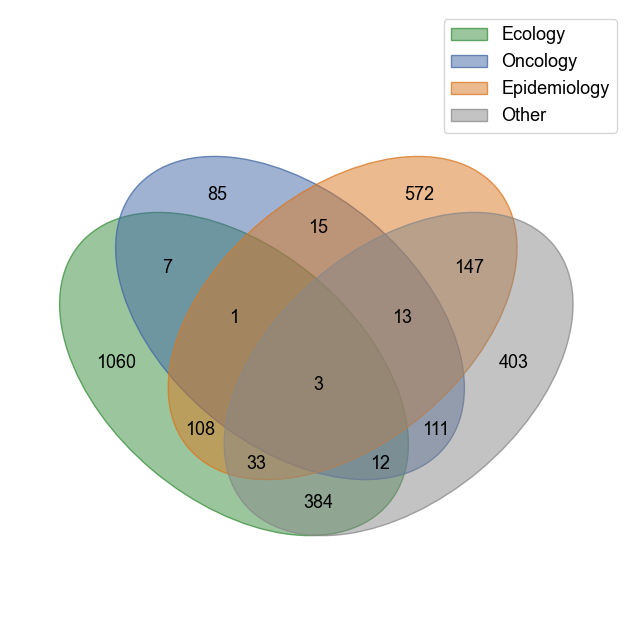


Number of unique ORCID authors and articles per subfield (2+ papers):


,Subfield,Unique ORCID authors (2+ papers),Articles with 2+ paper authors
0,Ecology,1608,2024
1,Epidemiology,892,881
2,Oncology,247,234
3,Other,1106,1150


In [41]:

# -------------------------------------------------------------------
# Consistent figure fonts
# -------------------------------------------------------------------

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 11,
    "axes.labelsize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "pdf.fonttype": 42,
})

# ============================================================
# VENN DIAGRAM - FOUR BIOLOGICAL SUBFIELDS (AUTHORS WITH 2+ PAPERS)
# ============================================================

from venn import venn

# ============================================================
# ORCID SUBFIELD OVERLAPS - FOUR BIOLOGICAL SUBFIELDS (2+ PAPERS)
# ============================================================

# -------------------------------------------------------------------
# Use authors with at least 2 papers across all four subfields
# (already defined in the previous analysis cell)
# -------------------------------------------------------------------

print(f"Total ORCID authors (all): {len(orcid_to_categories)}")
print(f"Authors with at least 2 papers: {len(orcids_min2_4fields)}")
print(f"Authors excluded: {len(orcid_to_categories) - len(orcids_min2_4fields)}")


# -------------------------------------------------------------------
# Create one ORCID set for each biological subfield (2+ papers only)
# -------------------------------------------------------------------

eco_orcids_min2_4fields = set()
onco_orcids_min2_4fields = set()
epi_orcids_min2_4fields = set()
other_orcids_min2_4fields = set()

for orcid, categories in categories_min2_4fields.items():

    if "ecology" in categories:
        eco_orcids_min2_4fields.add(orcid)

    if "oncology" in categories:
        onco_orcids_min2_4fields.add(orcid)

    if "epidemiology" in categories:
        epi_orcids_min2_4fields.add(orcid)

    if "other" in categories:
        other_orcids_min2_4fields.add(orcid)


# -------------------------------------------------------------------
# Calculate the number of authors in each subfield (2+ papers)
# -------------------------------------------------------------------

field_totals_min2_4fields = {
    "ecology": len(eco_orcids_min2_4fields),
    "oncology": len(onco_orcids_min2_4fields),
    "epidemiology": len(epi_orcids_min2_4fields),
    "other": len(other_orcids_min2_4fields),
}

field_totals_df_min2_4fields = pd.DataFrame([
    {"field": field, "unique_orcid_authors": count}
    for field, count in field_totals_min2_4fields.items()
])


# -------------------------------------------------------------------
# Plot the four-subfield Venn diagram (2+ papers)
# -------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 8))

venn_sets_min2_4fields = {
    "Ecology": eco_orcids_min2_4fields,
    "Oncology": onco_orcids_min2_4fields,
    "Epidemiology": epi_orcids_min2_4fields,
    "Other": other_orcids_min2_4fields,
}

venn(
    venn_sets_min2_4fields,
    cmap=[
        colour_map["ecology"],
        colour_map["oncology"],
        colour_map["epidemiology"],
        colour_map["other"],
    ],
    alpha=0.5,
    ax=ax,
)

# Match the font size of all Venn diagram labels
for text in ax.texts:
    text.set_fontfamily("Arial")
    text.set_fontsize(13)

plt.savefig(
    ORCID_OUTPUT_DIR / "venn_2plus_papers.pdf",
    bbox_inches="tight",
)

plt.show()


# ============================================================
# SUMMARY: NUMBER OF AUTHORS AND ARTICLES PER SUBFIELD
# AUTHORS WITH AT LEAST 2 PAPERS
# ============================================================

# Count unique articles containing at least one author
# who has published at least 2 papers across the four subfields

article_counts_min2_4fields = {
    field: set()
    for field in ["ecology", "epidemiology", "oncology", "other"]
}

for record in records:

    ut = extract_field(record, "UT")
    category = extract_field(record, "KA")
    year = extract_field(record, "PY")
    ao = extract_field(record, "AO")

    if ut is None or category is None or year is None or ao is None:
        continue

    category = category.strip().lower()

    if category not in article_counts_min2_4fields:
        continue

    try:
        year = int(year)
    except ValueError:
        continue

    # Apply the same year restriction as the ORCID analysis
    if year < first_year_above_threshold:
        continue

    # Extract ORCID identifiers from the article's authors
    authors = [
        author.strip()
        for author in ao.split(";")
        if author.strip()
    ]

    article_orcids = [
        extract_orcid(author)
        for author in authors
    ]

    # Check whether at least one author has 2+ papers
    has_min2_author = any(
        orcid in orcids_min2_4fields
        for orcid in article_orcids
        if orcid
    )

    if has_min2_author:
        article_counts_min2_4fields[category].add(ut)


# ============================================================
# CREATE SUMMARY TABLE
# ============================================================

summary_rows_min2_4fields = []

for field in ["ecology", "epidemiology", "oncology", "other"]:

    summary_rows_min2_4fields.append({
        "Subfield": field.capitalize(),
        "Unique ORCID authors (2+ papers)": field_totals_min2_4fields[field],
        "Articles with 2+ paper authors": len(article_counts_min2_4fields[field])
    })

summary_df_min2_4fields = pd.DataFrame(summary_rows_min2_4fields)

print("\nNumber of unique ORCID authors and articles per subfield (2+ papers):")
display(summary_df_min2_4fields)


In [24]:

# ============================================================
# ORCID SUBFIELD OVERLAPS - EXCEL SPREADSHEET (AUTHORS WITH 2+ PAPERS)
# FOUR BIOLOGICAL SUBFIELDS
# ============================================================
# Requires the 4-subfield analysis cell and Venn cell
# to have been run first.

excel_path_min2_4fields = ORCID_OUTPUT_DIR / "orcid_field_overlap_summary_2plus_papers.xlsx"

with pd.ExcelWriter(excel_path_min2_4fields, engine="openpyxl") as writer:

    # Every ORCID author (2+ papers) who publishes in more than one biological subfield
    multi_field_df_min2_4fields.to_excel(
        writer,
        sheet_name="all_overlapping_orcids",
        index=False
    )

    # Number of unique ORCID authors (2+ papers) in each exact combination of subfields.
    # These are also the region counts shown in the Venn diagram.
    combination_df_min2_4fields.to_excel(
        writer,
        sheet_name="field_combination_counts",
        index=False
    )

    # Number and percentage of authors publishing in exactly 1, 2, 3, or 4 subfields
    overall_summary_df_min2_4fields.to_excel(
        writer,
        sheet_name="overall_summary",
        index=False
    )

    # OPTIONAL
    # Percentage of authors within each subfield who publish in exactly 1, 2, 3, or 4 subfields
    exact_field_df_min2_4fields.to_excel(
        writer,
        sheet_name="field_percentages",
        index=False
    )

    # Summary of the raw input data processed for each biological subfield
    # (not affected by the 2+ paper filter)
    file_summary.to_excel(
        writer,
        sheet_name="input_file_summary",
        index=False
    )

    # Total number of unique ORCID authors (2+ papers) in each subfield (Venn circle totals)
    field_totals_df_min2_4fields.to_excel(
        writer,
        sheet_name="field_totals",
        index=False
    )

    # -------------------------------------------------------------------
    # OPTIONAL: split all_overlapping_orcids into separate sheets
    # by exact subfield combination (e.g., eco_epi)
    # -------------------------------------------------------------------

    exact_overlap_dfs_min2_4fields = {}

    if not multi_field_df_min2_4fields.empty:

        # Group overlapping authors by their exact subfield combination
        for combo, group in multi_field_df_min2_4fields.groupby("fields", sort=True):

            # Create a valid Excel worksheet name (max 31 characters)
            sheet_name = combo.replace(" + ", "_")
            sheet_name = sheet_name.replace("epidemiology", "epi")
            sheet_name = sheet_name.replace("ecology", "eco")
            sheet_name = sheet_name.replace("oncology", "onco")
            sheet_name = sheet_name[:31]

            exact_overlap_dfs_min2_4fields[combo] = group

            group.to_excel(
                writer,
                sheet_name=sheet_name,
                index=False,
            )

    # Make the workbook easier to read
    for sheet_name, worksheet in writer.sheets.items():
        worksheet.freeze_panes = "A2"

        # Add autofilter to the used range
        if worksheet.max_row > 1 and worksheet.max_column > 1:
            worksheet.auto_filter.ref = worksheet.dimensions

        # Automatically adjust each column width
        for column_cells in worksheet.columns:
            max_length = 0
            col_letter = column_cells[0].column_letter

            for cell in column_cells:
                value = cell.value
                if value is None:
                    continue
                max_length = max(max_length, len(str(value)))

            worksheet.column_dimensions[col_letter].width = min(max(max_length + 2, 12), 45)

print(f"\nExcel workbook saved: {excel_path_min2_4fields}")

print("\nVenn region counts (authors with 2+ papers)")
print(combination_df_min2_4fields.to_string(index=False))

print("\nSubfield circle totals (authors with 2+ papers)")
print(field_totals_df_min2_4fields.to_string(index=False))



Excel workbook saved: outputs/orcid_field_overlap_outputs/orcid_field_overlap_summary_2plus_papers.xlsx

Venn region counts (authors with 2+ papers)
 number_of_fields                         field_combination  unique_orcid_authors  percent_of_all_unique_orcid_authors
                1                                   ecology                  1060                            35.883548
                1                              epidemiology                   572                            19.363575
                1                                  oncology                    85                             2.877454
                1                                     other                   403                            13.642519
                2                    ecology + epidemiology                   108                             3.656060
                2                        ecology + oncology                     7                             0.236967
                2


Ecology (n = 1608 authors):
  1 subfield(s): 65.92%
  2 subfield(s): 31.03%
  3 subfield(s): 2.86%
  4 subfield(s): 0.19%

Epidemiology (n = 892 authors):
  1 subfield(s): 64.13%
  2 subfield(s): 30.27%
  3 subfield(s): 5.27%
  4 subfield(s): 0.34%

Oncology (n = 247 authors):
  1 subfield(s): 34.41%
  2 subfield(s): 53.85%
  3 subfield(s): 10.53%
  4 subfield(s): 1.21%

Other (n = 1106 authors):
  1 subfield(s): 36.44%
  2 subfield(s): 58.05%
  3 subfield(s): 5.24%
  4 subfield(s): 0.27%


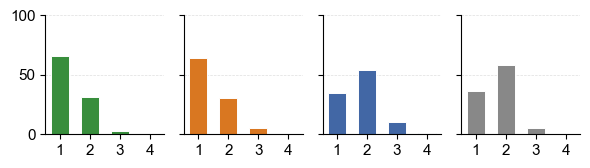

In [25]:

# ============================================================
# PLOT: NUMBER OF SUBFIELDS PER AUTHOR - 1 x 4 BAR CHART
# (AUTHORS WITH 2+ PAPERS ACROSS FOUR SUBFIELDS)
# ============================================================
# Requires the 4-subfield Venn cell to have been run first.

from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 10,
    "axes.labelsize": 11,
    "xtick.labelsize": 12,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "pdf.fonttype": 42,
})

# Use the same ORCID sets as the 4-subfield Venn diagram
authors_by_field_min2_4fields = {
    "ecology": eco_orcids_min2_4fields,
    "epidemiology": epi_orcids_min2_4fields,
    "oncology": onco_orcids_min2_4fields,
    "other": other_orcids_min2_4fields,
}

def plot_author_field_memberships_4fields(authors_by_field, output_filename):

    fields = ["ecology", "epidemiology", "oncology", "other"]

    # Count how many different subfields each author publishes in
    author_field_count = Counter()

    for field in fields:
        for orcid in authors_by_field[field]:
            author_field_count[orcid] += 1

    fig, axes = plt.subplots(
        1, 4,
        figsize=(6, 2.5),
        sharex=True,
        sharey=True
    )

    for i, field in enumerate(fields):

        ax = axes[i]

        # Authors belonging to this subfield
        field_authors = authors_by_field[field]
        total_authors = len(field_authors)

        # Calculate percentages for 1, 2, 3 and 4 subfields
        percentages = []

        for n_fields in range(1, 5):

            count = sum(
                author_field_count[orcid] == n_fields
                for orcid in field_authors
            )

            percentage = (
                100 * count / total_authors
                if total_authors > 0 else 0
            )

            percentages.append(percentage)

        # ---------------------------------------------
        # Print percentages to terminal
        # ---------------------------------------------

        print(f"\n{field.capitalize()} (n = {total_authors} authors):")

        for n_fields, percentage in enumerate(percentages, start=1):
            print(f"  {n_fields} subfield(s): {percentage:.2f}%")

        # ---------------------------------------------
        # Plot bars
        # ---------------------------------------------

        ax.bar(
            [1, 2, 3, 4],
            percentages,
            color=colour_map[field],
            width=0.6,
            edgecolor="white",
            linewidth=0.7
        )

        # ---------------------------------------------
        # Format axes
        # ---------------------------------------------

        ax.set_box_aspect(1)

        ax.tick_params(axis="x", labelsize=11)
        ax.tick_params(axis="y", labelsize=11)

        ax.set_xticks([1, 2, 3, 4])
        ax.set_ylim(0, 100)

        ax.set_axisbelow(True)
        ax.grid(
            axis="y",
            linestyle="--",
            linewidth=0.5,
            alpha=0.25,
            color="grey"
        )

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    # ---------------------------------------------
    # Save figure
    # ---------------------------------------------

    plt.tight_layout()

    fig.savefig(
        ORCID_OUTPUT_DIR / output_filename,
        bbox_inches="tight"
    )

    plt.show()


plot_author_field_memberships_4fields(
    authors_by_field_min2_4fields,
    output_filename="author_subfield_memberships_2plus_papers_4fields.pdf",
)


## Permutation test (4 subfields, >1 article)

In [26]:

# ============================================================
# PERMUTATION TEST: AUTHOR SUBFIELD OVERLAP - FOUR SUBFIELDS
# ============================================================

# Test whether ORCID-identified authors contribute to multiple biological
# subfields less frequently than would be expected from their publication
# frequency and the number of articles in each subfield.
#
# Subfield labels are randomly shuffled between articles published in the
# same year. The articles associated with each author remain unchanged,
# preserving the number and timing of papers published by each author.


# -------------------------------------------------------------------
# 1. COLLECT ARTICLES AND ORCID-IDENTIFIED AUTHORS
# -------------------------------------------------------------------

# Store the publication year, original subfield, and ORCID authors
# associated with each article
author_article_lookup_4fields = {}

# Subfields included in the author-overlap analysis
AUTHOR_FIELDS_4fields = [
    "ecology",
    "epidemiology",
    "oncology",
    "other"
]

for record in records:

    ut = extract_field(record, "UT")
    category = extract_field(record, "KA")
    year = extract_field(record, "PY")
    ao = extract_field(record, "AO")

    # Skip articles missing information required for the analysis
    if ut is None or category is None or year is None or ao is None:
        continue

    category = category.strip().lower()

    # Keep only the four biological subfields
    if category not in AUTHOR_FIELDS_4fields:
        continue

    # Convert the year into a number
    try:
        year = int(year)
    except ValueError:
        continue

    # Only include years from which all subfields remain above 50% ORCID coverage
    if year < first_year_above_threshold:
        continue

    # Collect the ORCID iDs associated with this article
    article_orcids = []

    authors = [
        author.strip()
        for author in ao.split(";")
        if author.strip()
    ]

    for author in authors:

        orcid = extract_orcid(author)

        if orcid:
            article_orcids.append(orcid)

    # Store articles containing at least one ORCID-identified author
    if article_orcids:
        author_article_lookup_4fields[ut] = {
            "year": year,
            "field": category,
            "orcids": article_orcids,
        }


# -------------------------------------------------------------------
# 2. CALCULATE THE NUMBER OF PAPERS PER AUTHOR
# -------------------------------------------------------------------

# Store the number of articles associated with each unique ORCID iD
papers_per_author_4fields = defaultdict(int)

for ut, info in author_article_lookup_4fields.items():

    for orcid in info["orcids"]:
        papers_per_author_4fields[orcid] += 1


# Create a dataframe containing the publication count for each author
papers_per_author_rows_4fields = []

for orcid, paper_count in papers_per_author_4fields.items():

    papers_per_author_rows_4fields.append({
        "orcid_id": orcid,
        "number_of_papers": paper_count,
    })

papers_per_author_df_4fields = pd.DataFrame(
    papers_per_author_rows_4fields
).sort_values(
    ["number_of_papers", "orcid_id"],
    ascending=[False, True],
)


print("\nNumber of papers per ORCID-identified author:")
print(
    papers_per_author_df_4fields["number_of_papers"].describe()
)


# -------------------------------------------------------------------
# 3. CALCULATE OBSERVED AUTHOR OVERLAP (AUTHORS WITH 2+ PAPERS)
# -------------------------------------------------------------------

# Use exactly the same eligible authors as the four-subfield Venn diagram

def calculate_author_overlap_4fields(article_lookup):

    author_fields = defaultdict(set)

    for ut, info in article_lookup.items():

        field = info["field"]

        for orcid in info["orcids"]:

            # Exclude authors not included in the four-subfield Venn diagram
            if orcid not in orcids_min2_4fields:
                continue

            author_fields[orcid].add(field)

    overlap_percentages = {}

    for field in AUTHOR_FIELDS_4fields:

        field_authors = [
            orcid
            for orcid, fields in author_fields.items()
            if field in fields
        ]

        overlapping_authors = sum(
            len(author_fields[orcid]) > 1
            for orcid in field_authors
        )

        overlap_percentages[field] = (
            100 * overlapping_authors / len(field_authors)
            if field_authors else 0
        )

    return overlap_percentages


observed_author_overlap_4fields = calculate_author_overlap_4fields(
    author_article_lookup_4fields
)


# -------------------------------------------------------------------
# 4. SHUFFLE ARTICLE SUBFIELD LABELS WITHIN PUBLICATION YEARS
# -------------------------------------------------------------------

# Randomly shuffle the subfield labels between articles published
# in the same year while keeping each author's articles unchanged
def shuffle_author_article_fields_4fields(
    article_lookup,
    rng,
):

    shuffled_lookup = {}

    # Group article UTs by publication year
    articles_by_year = defaultdict(list)

    for ut, info in article_lookup.items():
        articles_by_year[info["year"]].append(ut)

    # Shuffle the existing subfield labels separately within each year
    for year, uts in articles_by_year.items():

        fields = []

        # Get original field label
        for ut in uts:
            fields.append(
                article_lookup[ut]["field"]
            )

        # Randomly shuffle the labels
        shuffled_fields = rng.permutation(fields)

        # Assign the shuffled subfield labels back to the articles
        for i in range(len(uts)):

            ut = uts[i]
            shuffled_field = shuffled_fields[i]

            shuffled_lookup[ut] = {
                "year": article_lookup[ut]["year"],
                "field": shuffled_field,
                "orcids": article_lookup[ut]["orcids"],
            }

    return shuffled_lookup


# -------------------------------------------------------------------
# 5. RUN THE PERMUTATION TEST
# -------------------------------------------------------------------

N_AUTHOR_PERMUTATIONS_4fields = 1000
AUTHOR_RANDOM_SEED_4fields = 42

author_rng_4fields = np.random.default_rng(
    AUTHOR_RANDOM_SEED_4fields
)


# Store the author overlap percentage from every permutation
author_permutation_results_4fields = {}

for field in AUTHOR_FIELDS_4fields:
    author_permutation_results_4fields[field] = []


# Repeat the label shuffling and author overlap calculation
for _ in range(N_AUTHOR_PERMUTATIONS_4fields):

    # Shuffle article subfield labels within publication years
    shuffled_author_lookup_4fields = shuffle_author_article_fields_4fields(
        author_article_lookup_4fields,
        author_rng_4fields,
    )

    # Calculate author overlap using the shuffled article labels
    shuffled_overlap_4fields = calculate_author_overlap_4fields(
        shuffled_author_lookup_4fields
    )

    # Store the result for each subfield
    for field in AUTHOR_FIELDS_4fields:
        author_permutation_results_4fields[field].append(
            shuffled_overlap_4fields[field]
        )


# -------------------------------------------------------------------
# 6. SUMMARISE THE PERMUTATION RESULTS
# -------------------------------------------------------------------

author_summary_rows_4fields = []

for field in AUTHOR_FIELDS_4fields:

    # Get the 1,000 author overlap percentages obtained
    # from the shuffled article labels
    null_values = np.array(
        author_permutation_results_4fields[field]
    )

    # Get the actual observed author overlap percentage
    observed = observed_author_overlap_4fields[field]

    # Calculate the mean author overlap across the permutations
    null_mean = null_values.mean()

    # Calculate the central 95% interval of the permutation distribution
    null_lower = np.percentile(
        null_values,
        2.5
    )

    null_upper = np.percentile(
        null_values,
        97.5
    )

    # Test whether observed author overlap is lower than expected
    # under random assignment of article subfield labels
    # The +1 correction avoids reporting a misleading p-value of zero
    p_value = (
        np.sum(null_values <= observed) + 1
    ) / (
        N_AUTHOR_PERMUTATIONS_4fields + 1
    )

    author_summary_rows_4fields.append({
        "field": field,
        "observed_overlap_percent": observed,
        "null_mean_percent": null_mean,
        "null_2.5_percent": null_lower,
        "null_97.5_percent": null_upper,
        "p_value": p_value,
    })


author_permutation_summary_4fields = pd.DataFrame(
    author_summary_rows_4fields
)

print("\nAuthor overlap permutation test results (four subfields):")

display(
    author_permutation_summary_4fields.round(3)
)


# -------------------------------------------------------------------
# 7. SAVE RESULTS
# -------------------------------------------------------------------

AUTHOR_PERMUTATION_OUTPUT_FILE_4fields = (
    ORCID_OUTPUT_DIR /
    "author_overlap_permutation_analysis_4fields.xlsx"
)

with pd.ExcelWriter(
    AUTHOR_PERMUTATION_OUTPUT_FILE_4fields,
    engine="openpyxl",
) as writer:

    papers_per_author_df_4fields.to_excel(
        writer,
        sheet_name="papers_per_author",
        index=False,
    )

    author_permutation_summary_4fields.to_excel(
        writer,
        sheet_name="permutation_summary",
        index=False,
    )

print(
    f"\nAuthor permutation results saved to: "
    f"{AUTHOR_PERMUTATION_OUTPUT_FILE_4fields}"
)


Number of papers per ORCID-identified author:
count    11289.000000
mean         1.601648
std          1.797402
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max         54.000000
Name: number_of_papers, dtype: float64

Author overlap permutation test results (four subfields):


,field,observed_overlap_percent,null_mean_percent,null_2.5_percent,null_97.5_percent,p_value
0,ecology,34.080,82.244,80.345,84.052,0.001
1,epidemiology,35.874,94.038,92.405,95.553,0.001
2,oncology,65.587,98.874,97.373,99.800,0.001
3,other,63.562,91.839,90.176,93.364,0.001



Author permutation results saved to: outputs/orcid_field_overlap_outputs/author_overlap_permutation_analysis_4fields.xlsx


In [27]:
# ============================================================
# CHECK: VENN VS PERMUTATION TEST - FOUR SUBFIELDS
# ============================================================

eligible_orcids_4fields = {
    orcid
    for orcid, count in papers_per_author_4fields.items()
    if count >= 2
}

print(
    "Do the Venn diagram and permutation test use the same authors?",
    eligible_orcids_4fields == orcids_min2_4fields
)

print(
    "Authors only in the permutation test:",
    len(eligible_orcids_4fields - orcids_min2_4fields)
)

print(
    "Authors only in the Venn diagram:",
    len(orcids_min2_4fields - eligible_orcids_4fields)
)

Do the Venn diagram and permutation test use the same authors? True
Authors only in the permutation test: 0
Authors only in the Venn diagram: 0


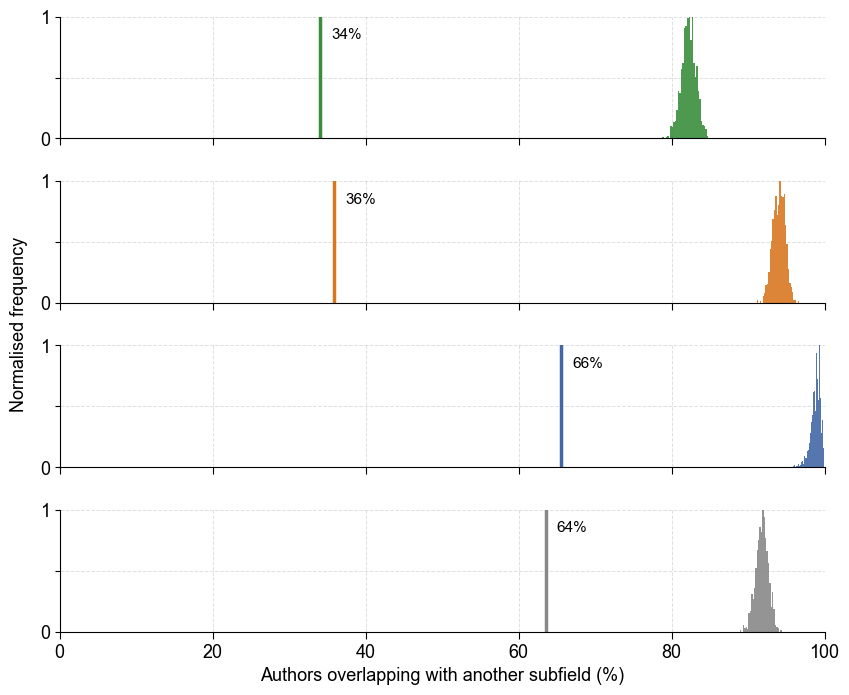

In [28]:

# ============================================================
# PLOT: AUTHOR OVERLAP PERMUTATION DISTRIBUTIONS - FOUR SUBFIELDS
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 11,
    "axes.labelsize": 13,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 11,
    "pdf.fonttype": 42,
})

def plot_author_permutation_results_4fields(
    author_permutation_results_4fields,
    observed_author_overlap_4fields,
):

    # Create vertically stacked panels
    fig, axes = plt.subplots(
        len(AUTHOR_FIELDS_4fields), 1,
        figsize=(9, 7.5),
        sharex=True
    )

    # Plot each subfield separately
    for i, field in enumerate(AUTHOR_FIELDS_4fields):

        ax = axes[i]

        null_values = author_permutation_results_4fields[field]
        observed = observed_author_overlap_4fields[field]

        # ---------------------------------------------
        # Permutation distribution
        # ---------------------------------------------

        counts, bin_edges = np.histogram(null_values, bins=30)

        ax.hist(
            null_values,
            bins=bin_edges,
            weights=np.ones(len(null_values)) / counts.max(),
            color=colour_map[field],
            alpha=0.9
        )

        # ---------------------------------------------
        # Observed value
        # ---------------------------------------------

        ax.axvline(
            observed,
            color=colour_map[field],
            linewidth=2.5,
            linestyle="-"
        )

        # Add observed percentage beside the line
        ax.annotate(
            f"{observed:.0f}%",
            xy=(observed, 0.85),
            xycoords=("data", "axes fraction"),
            xytext=(8, 0),
            textcoords="offset points",
            ha="left",
            va="center",
            fontsize=11,
            color="black",
            #fontweight="bold"
        )

        """
        # ---------------------------------------------
        # Subfield label on the left
        # ---------------------------------------------

        ax.set_ylabel(
            field.capitalize(),
            rotation=0,
            ha="right",
            va="center",
            labelpad=20,
            fontsize=12
        )
        """

        # ---------------------------------------------
        # Format axes
        # ---------------------------------------------

        # X-axis: author overlap percentage
        ax.set_xlim(0, 100)

        # Y-axis: normalised frequency
        ax.set_ylim(0, 1)
        ax.set_yticks([0, 0.5, 1])
        ax.set_yticklabels(["0", "", "1"])

        ax.tick_params(
            axis="y",
            left=True,
            labelleft=True,
            labelsize=13
        )

        # Remove top and right borders
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        # Keep left and bottom axes black
        ax.spines["left"].set_visible(True)
        ax.spines["left"].set_color("black")
        ax.spines["left"].set_linewidth(0.8)

        ax.spines["bottom"].set_visible(True)
        ax.spines["bottom"].set_color("black")
        ax.spines["bottom"].set_linewidth(0.8)

        # ---------------------------------------------
        # X-axis ticks on ALL panels
        # ---------------------------------------------

        ax.set_xticks(range(0, 101, 20))

        ax.tick_params(
            axis="x",
            which="major",
            bottom=True,
            labelbottom=(i == len(AUTHOR_FIELDS_4fields) - 1),
            length=5,
            width=0.8,
            labelsize=13
        )

        # ---------------------------------------------
        # Faint horizontal grid lines
        # ---------------------------------------------

        ax.set_axisbelow(True)

        ax.yaxis.grid(
            True,
            linestyle="--",
            color="grey",
            alpha=0.25,
            linewidth=0.7
        )

        # ---------------------------------------------
        # Faint vertical grid lines
        # ---------------------------------------------

        ax.set_axisbelow(True)

        ax.xaxis.grid(
            True,
            linestyle="--",
            color="grey",
            alpha=0.25,
            linewidth=0.7
        )

    # ---------------------------------------------
    # Shared axis label
    # ---------------------------------------------

    axes[-1].set_xlabel(
        "Authors overlapping with another subfield (%)",
        fontsize=13,
    )

    fig.text(
        0.055,
        0.54,
        "Normalised frequency",
        rotation=90,
        fontsize=13,
        ha="center",
        va="center"
    )

    # ---------------------------------------------
    # Layout and save
    # ---------------------------------------------

    plt.subplots_adjust(
        left=0.10,
        right=0.95,
        top=0.95,
        bottom=0.13,
        hspace=0.35
    )

    fig.savefig(
        ORCID_OUTPUT_DIR /
        "author_overlap_permutation_distributions_4fields.pdf",
        bbox_inches="tight"
    )

    plt.show()


plot_author_permutation_results_4fields(
    author_permutation_results_4fields,
    observed_author_overlap_4fields,
)


# Analysis for authors who have at least 2 papers, and excluding other biology

In [66]:

# ============================================================
# ORCID SUBFIELD OVERLAPS - ANALYSIS OF DATA (AUTHORS WITH 2+ PAPERS)
# THREE BIOLOGICAL SUBFIELDS
# ============================================================
# Naming convention:
#   orcid_to_categories / orcid_to_counts / orcid_to_names = ALL ORCID authors
#   *_min2_3fields = authors with at least 2 papers across the 3 subfields
# This prevents the 3-subfield and 4-subfield analyses
# from overwriting each other.

# ============================================================
# RESTRICT ORCID ANALYSIS TO AUTHORS WITH AT LEAST TWO PUBLICATIONS
# ============================================================

MIN_PUBLICATIONS = 2

FIELDS_MIN2_3fields = ["ecology", "epidemiology", "oncology"]

# Keep only ORCID authors with at least two publication occurrences
# across the three biological subfields
orcids_min2_3fields = {
    orcid
    for orcid, counts in orcid_to_counts.items()
    if sum(counts.get(field, 0) for field in FIELDS_MIN2_3fields) >= MIN_PUBLICATIONS
}

# Dictionary containing only the 2+ paper authors
# and the biological subfields they have published in
categories_min2_3fields = {
    orcid: set(categories) & set(FIELDS_MIN2_3fields)
    for orcid, categories in orcid_to_categories.items()
    if orcid in orcids_min2_3fields
}

print(f"Total ORCID authors (all): {len(orcid_to_categories)}")
print(f"Authors with at least {MIN_PUBLICATIONS} publications: {len(categories_min2_3fields)}")


# -------------------------------------------------------------------
# Analyse ORCID overlap across biological subfields (2+ papers)
# -------------------------------------------------------------------

exact_field_rows_min2_3fields = []

for field in FIELDS_MIN2_3fields:

    # Identify all the unique ORCID iDs (2+ papers) that appear in this subfield
    field_orcids_min2_3fields = {
        orcid
        for orcid, categories in categories_min2_3fields.items()
        if field in categories
    }

    total_field_orcids_min2_3fields = len(field_orcids_min2_3fields)

    # Begin the summary row for this field
    row = {
        "field": field,
        "total_unique_orcids_in_field": total_field_orcids_min2_3fields,
    }

    # Count authors in this field who appear in exactly 1, 2, or 3 biological subfields
    for n in [1, 2, 3]:
        count_n = sum(
            1 for orcid in field_orcids_min2_3fields
            if len(categories_min2_3fields[orcid]) == n
        )

        # Percentage of authors in this subfield who appear in exactly n subfields
        row[f"orcids_in_exactly_{n}_field(s)"] = count_n
        row[f"percent_in_exactly_{n}_field(s)"] = (
            count_n / total_field_orcids_min2_3fields * 100
            if total_field_orcids_min2_3fields > 0 else 0
        )

    exact_field_rows_min2_3fields.append(row)

exact_field_df_min2_3fields = pd.DataFrame(exact_field_rows_min2_3fields)


# -------------------------------------------------------------------
# Overall subfield combination counts (2+ papers)
# -------------------------------------------------------------------

combination_counts_min2_3fields = defaultdict(int)

for orcid, categories in categories_min2_3fields.items():
    combo = tuple(sorted(categories))
    combination_counts_min2_3fields[combo] += 1

# Total number of unique ORCID authors with 2+ papers
total_orcids_min2_3fields = len(categories_min2_3fields)

combination_rows_min2_3fields = []

for combo, count in combination_counts_min2_3fields.items():

    # One summary row for this exact subfield combination
    combination_rows_min2_3fields.append({
        "number_of_fields": len(combo),
        "field_combination": " + ".join(combo),
        "unique_orcid_authors": count,
        "percent_of_all_unique_orcid_authors": (
            count / total_orcids_min2_3fields * 100
            if total_orcids_min2_3fields > 0 else 0
        )
    })

combination_df_min2_3fields = pd.DataFrame(combination_rows_min2_3fields)

# Sort first by number of subfields, then alphabetically
combination_df_min2_3fields = combination_df_min2_3fields.sort_values(
    ["number_of_fields", "field_combination"],
    ascending=[True, True]
)


# -------------------------------------------------------------------
# ORCID IDs in multiple fields (2+ papers)
# -------------------------------------------------------------------

multi_field_rows_min2_3fields = []

for orcid, categories in categories_min2_3fields.items():

    # Only authors who publish in more than one biological subfield
    if len(categories) > 1:

        multi_field_rows_min2_3fields.append({
            "orcid_id": orcid,
            "author_names_seen": "; ".join(sorted(orcid_to_names[orcid])),
            "number_of_fields": len(categories),
            "fields": " + ".join(sorted(categories)),
            "ecology_count": orcid_to_counts[orcid].get("ecology", 0),
            "oncology_count": orcid_to_counts[orcid].get("oncology", 0),
            "epidemiology_count": orcid_to_counts[orcid].get("epidemiology", 0),
            "total_author_occurrences": sum(
                orcid_to_counts[orcid].get(field, 0)
                for field in FIELDS_MIN2_3fields
            ),
        })

multi_field_df_min2_3fields = pd.DataFrame(multi_field_rows_min2_3fields)

# Sort by number of subfields, then by total author occurrences
if not multi_field_df_min2_3fields.empty:
    multi_field_df_min2_3fields = multi_field_df_min2_3fields.sort_values(
        ["number_of_fields", "total_author_occurrences", "orcid_id"],
        ascending=[False, False, True]
    )


# -------------------------------------------------------------------
# Overall summary (2+ papers)
# -------------------------------------------------------------------

summary_rows_min2_3fields = []

# Authors publishing in 1, 2, or 3 biological subfields
for n in [1, 2, 3]:

    count_n = sum(
        1 for categories in categories_min2_3fields.values()
        if len(categories) == n
    )

    summary_rows_min2_3fields.append({
        "number_of_fields": n,
        "unique_orcid_authors": count_n,
        "percent_of_all_unique_orcid_authors": (
            count_n / total_orcids_min2_3fields * 100
            if total_orcids_min2_3fields > 0 else 0
        )
    })

overall_summary_df_min2_3fields = pd.DataFrame(summary_rows_min2_3fields)


# -------------------------------------------------------------------
# Input summary (raw input, not affected by the 2+ paper filter)
# -------------------------------------------------------------------

file_summary = pd.DataFrame([
    {
        "category": category,
        "records_read": records_read.get(category, 0),
        "author_occurrences_read": authors_read.get(category, 0),
        "author_occurrences_with_orcid": authors_with_orcid_read.get(category, 0),
    }
    for category in FIELDS
])


# -------------------------------------------------------------------
# Print the percentages quoted in the text (2+ papers)
# -------------------------------------------------------------------

print("\nOverall author overlap (authors with 2+ papers only):")
print(f"Total ORCID authors with 2+ papers: {total_orcids_min2_3fields}")

for _, row in overall_summary_df_min2_3fields.iterrows():
    print(
        f"  Exactly {int(row['number_of_fields'])} field(s): "
        f"{int(row['unique_orcid_authors'])} authors "
        f"({row['percent_of_all_unique_orcid_authors']:.2f}%)"
    )

print("\nPer-subfield author overlap, 2+ papers (% also in at least one other subfield):")

for _, row in exact_field_df_min2_3fields.iterrows():
    overlap_percent = 100 - row["percent_in_exactly_1_field(s)"]
    overlap_count = (
        row["total_unique_orcids_in_field"]
        - row["orcids_in_exactly_1_field(s)"]
    )
    print(
        f"  {row['field']}: {overlap_percent:.2f}% "
        f"({int(overlap_count)} of {int(row['total_unique_orcids_in_field'])} authors)"
    )


Total ORCID authors (all): 11289
Authors with at least 2 publications: 2195

Overall author overlap (authors with 2+ papers only):
Total ORCID authors with 2+ papers: 2195
  Exactly 1 field(s): 2003 authors (91.25%)
  Exactly 2 field(s): 188 authors (8.56%)
  Exactly 3 field(s): 4 authors (0.18%)

Per-subfield author overlap, 2+ papers (% also in at least one other subfield):
  ecology: 11.67% (164 of 1405 authors)
  epidemiology: 21.44% (173 of 807 authors)
  oncology: 28.49% (51 of 179 authors)


Total ORCID authors (all): 11289
Authors with at least 2 papers in the 3 subfields: 2195
Authors excluded: 9094


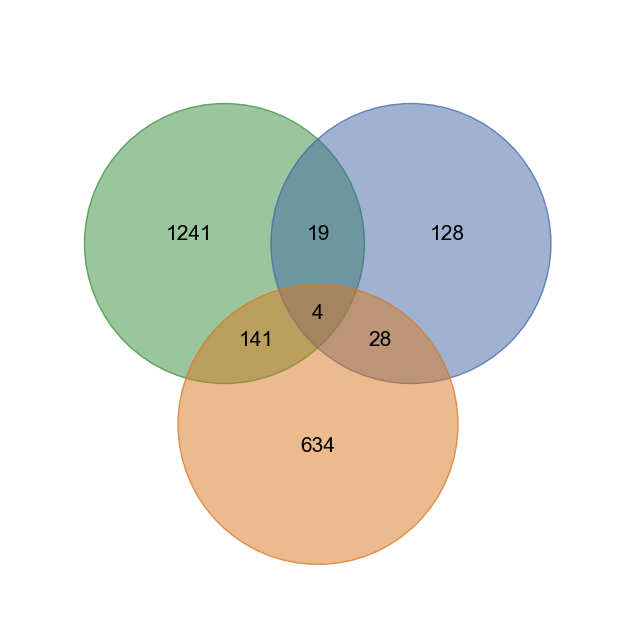


Number of unique ORCID authors and articles per subfield (2+ papers):


,Subfield,Unique ORCID authors (2+ papers),Articles with 2+ paper authors
0,Ecology,1405,1942
1,Epidemiology,807,850
2,Oncology,179,208


In [73]:
# -------------------------------------------------------------------
# Consistent figure fonts
# -------------------------------------------------------------------

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 13,
    "axes.labelsize": 13,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 13,
    "pdf.fonttype": 42,
})

# ============================================================
# VENN DIAGRAM - THREE BIOLOGICAL SUBFIELDS (AUTHORS WITH 2+ PAPERS)
# ============================================================

from venn import venn

# ============================================================
# ORCID SUBFIELD OVERLAPS - THREE BIOLOGICAL SUBFIELDS (2+ PAPERS)
# ============================================================

# -------------------------------------------------------------------
# Use authors with at least 2 papers across the 3 subfields
# (already defined in the previous analysis cell)
# -------------------------------------------------------------------

print(f"Total ORCID authors (all): {len(orcid_to_categories)}")
print(f"Authors with at least 2 papers in the 3 subfields: {len(orcids_min2_3fields)}")
print(f"Authors excluded: {len(orcid_to_categories) - len(orcids_min2_3fields)}")


# -------------------------------------------------------------------
# Create one ORCID set for each biological subfield (2+ papers only)
# -------------------------------------------------------------------

eco_orcids_min2_3fields = set()
onco_orcids_min2_3fields = set()
epi_orcids_min2_3fields = set()

for orcid, categories in categories_min2_3fields.items():

    if "ecology" in categories:
        eco_orcids_min2_3fields.add(orcid)

    if "oncology" in categories:
        onco_orcids_min2_3fields.add(orcid)

    if "epidemiology" in categories:
        epi_orcids_min2_3fields.add(orcid)


# -------------------------------------------------------------------
# Calculate the number of authors in each subfield (2+ papers)
# -------------------------------------------------------------------

field_totals_min2_3fields = {
    "ecology": len(eco_orcids_min2_3fields),
    "oncology": len(onco_orcids_min2_3fields),
    "epidemiology": len(epi_orcids_min2_3fields),
}

field_totals_df_min2_3fields = pd.DataFrame([
    {"field": field, "unique_orcid_authors": count}
    for field, count in field_totals_min2_3fields.items()
])


# -------------------------------------------------------------------
# Plot the three-subfield Venn diagram (2+ papers)
# -------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 8))

venn_sets_min2_3fields = {
    "Ecology": eco_orcids_min2_3fields,
    "Oncology": onco_orcids_min2_3fields,
    "Epidemiology": epi_orcids_min2_3fields,
}

venn(
    venn_sets_min2_3fields,
    cmap=[
        colour_map["ecology"],
        colour_map["oncology"],
        colour_map["epidemiology"],
    ],
    alpha=0.5,
    ax=ax,
)

# Remove numbers inside the Venn diagram
"""
for text in ax.texts:
    if text.get_text().strip().isdigit():
        text.set_visible(False)
"""

# Match the font size of all Venn diagram labels
for text in ax.texts:
    text.set_fontfamily("Arial")
    text.set_fontsize(15)

# Remove the legend
if ax.get_legend() is not None:
    ax.get_legend().remove()

plt.savefig(
    ORCID_OUTPUT_DIR / "venn_2plus_papers_3fields.pdf",
    bbox_inches="tight",
)

plt.show()


# ============================================================
# SUMMARY: NUMBER OF AUTHORS AND ARTICLES PER SUBFIELD
# AUTHORS WITH AT LEAST 2 PAPERS
# ============================================================

# Count unique articles containing at least one author
# who has published at least 2 papers across the 3 subfields

article_counts_min2_3fields = {
    field: set()
    for field in FIELDS_MIN2_3fields
}

for record in records:

    ut = extract_field(record, "UT")
    category = extract_field(record, "KA")
    year = extract_field(record, "PY")
    ao = extract_field(record, "AO")

    if ut is None or category is None or year is None or ao is None:
        continue

    category = category.strip().lower()

    if category not in article_counts_min2_3fields:
        continue

    try:
        year = int(year)
    except ValueError:
        continue

    # Apply the same year restriction as the ORCID analysis
    if year < first_year_above_threshold:
        continue

    # Extract ORCID identifiers from the article's authors
    authors = [
        author.strip()
        for author in ao.split(";")
        if author.strip()
    ]

    article_orcids = [
        extract_orcid(author)
        for author in authors
    ]

    # Check whether at least one author has 2+ papers
    # across Ecology, Epidemiology and Oncology
    has_min2_author = any(
        orcid in orcids_min2_3fields
        for orcid in article_orcids
        if orcid
    )

    if has_min2_author:
        article_counts_min2_3fields[category].add(ut)


# ============================================================
# CREATE SUMMARY TABLE
# ============================================================

summary_rows_min2_3fields = []

for field in FIELDS_MIN2_3fields:

    summary_rows_min2_3fields.append({
        "Subfield": field.capitalize(),
        "Unique ORCID authors (2+ papers)": field_totals_min2_3fields[field],
        "Articles with 2+ paper authors": len(article_counts_min2_3fields[field])
    })

summary_df_min2_3fields = pd.DataFrame(summary_rows_min2_3fields)

print("\nNumber of unique ORCID authors and articles per subfield (2+ papers):")
display(summary_df_min2_3fields)


In [31]:

# ============================================================
# ORCID SUBFIELD OVERLAPS - EXCEL SPREADSHEET (AUTHORS WITH 2+ PAPERS)
# THREE BIOLOGICAL SUBFIELDS
# ============================================================
# Requires the 3-subfield analysis cell (and the Venn cell, for field_totals_df_min2_3fields)
# to have been run first.

excel_path_min2_3fields = ORCID_OUTPUT_DIR / "orcid_field_overlap_summary_2plus_papers_3fields.xlsx"

with pd.ExcelWriter(excel_path_min2_3fields, engine="openpyxl") as writer:

    # Every ORCID author (2+ papers) who publishes in more than one biological subfield
    multi_field_df_min2_3fields.to_excel(
        writer,
        sheet_name="all_overlapping_orcids",
        index=False
    )

    # Number of unique ORCID authors (2+ papers) in each exact combination of subfields.
    # These are also the region counts shown in the Venn diagram.
    combination_df_min2_3fields.to_excel(
        writer,
        sheet_name="field_combination_counts",
        index=False
    )

    # Number and percentage of authors publishing in exactly 1, 2, or 3 subfields
    overall_summary_df_min2_3fields.to_excel(
        writer,
        sheet_name="overall_summary",
        index=False
    )

    # OPTIONAL
    # Percentage of authors within each subfield who publish in exactly 1, 2, or 3 subfields
    exact_field_df_min2_3fields.to_excel(
        writer,
        sheet_name="field_percentages",
        index=False
    )

    # Summary of the raw input data processed for each biological subfield
    # (not affected by the 2+ paper filter)
    file_summary.to_excel(
        writer,
        sheet_name="input_file_summary",
        index=False
    )

    # Total number of unique ORCID authors (2+ papers) in each subfield (Venn circle totals)
    field_totals_df_min2_3fields.to_excel(
        writer,
        sheet_name="field_totals",
        index=False
    )

    # -------------------------------------------------------------------
    # OPTIONAL: split all_overlapping_orcids into separate sheets
    # by exact subfield combination (e.g., eco_epi)
    # -------------------------------------------------------------------

    exact_overlap_dfs_min2_3fields = {}

    if not multi_field_df_min2_3fields.empty:

        # Group overlapping authors by their exact subfield combination
        for combo, group in multi_field_df_min2_3fields.groupby("fields", sort=True):

            # Create a valid Excel worksheet name (max 31 characters)
            sheet_name = combo.replace(" + ", "_")
            sheet_name = sheet_name.replace("epidemiology", "epi")
            sheet_name = sheet_name.replace("ecology", "eco")
            sheet_name = sheet_name.replace("oncology", "onco")
            sheet_name = sheet_name[:31]

            exact_overlap_dfs_min2_3fields[combo] = group

            group.to_excel(
                writer,
                sheet_name=sheet_name,
                index=False,
            )

    # Make the workbook easier to read
    for sheet_name, worksheet in writer.sheets.items():
        worksheet.freeze_panes = "A2"

        # Add autofilter to the used range
        if worksheet.max_row > 1 and worksheet.max_column > 1:
            worksheet.auto_filter.ref = worksheet.dimensions

        # Automatically adjust each column width
        for column_cells in worksheet.columns:
            max_length = 0
            col_letter = column_cells[0].column_letter

            for cell in column_cells:
                value = cell.value
                if value is None:
                    continue
                max_length = max(max_length, len(str(value)))

            worksheet.column_dimensions[col_letter].width = min(max(max_length + 2, 12), 45)

print(f"\nExcel workbook saved: {excel_path_min2_3fields}")

print("\nVenn region counts (authors with 2+ papers)")
print(combination_df_min2_3fields.to_string(index=False))

print("\nSubfield circle totals (authors with 2+ papers)")
print(field_totals_df_min2_3fields.to_string(index=False))



Excel workbook saved: outputs/orcid_field_overlap_outputs/orcid_field_overlap_summary_2plus_papers_3fields.xlsx

Venn region counts (authors with 2+ papers)
 number_of_fields                 field_combination  unique_orcid_authors  percent_of_all_unique_orcid_authors
                1                           ecology                  1241                            56.537585
                1                      epidemiology                   634                            28.883827
                1                          oncology                   128                             5.831435
                2            ecology + epidemiology                   141                             6.423690
                2                ecology + oncology                    19                             0.865604
                2           epidemiology + oncology                    28                             1.275626
                3 ecology + epidemiology + oncology              


Ecology (n = 1405 authors):
  1 subfield(s): 88.33%
  2 subfield(s): 11.39%
  3 subfield(s): 0.28%

Epidemiology (n = 807 authors):
  1 subfield(s): 78.56%
  2 subfield(s): 20.94%
  3 subfield(s): 0.50%

Oncology (n = 179 authors):
  1 subfield(s): 71.51%
  2 subfield(s): 26.26%
  3 subfield(s): 2.23%


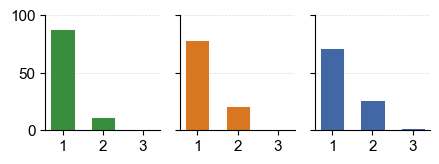

In [32]:

# ============================================================
# PLOT: NUMBER OF SUBFIELDS PER AUTHOR - 1 x 3 BAR CHART
# (AUTHORS WITH 2+ PAPERS ACROSS THE 3 SUBFIELDS)
# ============================================================
# Requires the 3-subfield Venn cell to have been run first.

from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 10,
    "axes.labelsize": 11,
    "xtick.labelsize": 12,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "pdf.fonttype": 42,
})

# Use the same ORCID sets as the 3-subfield Venn diagram
authors_by_field_min2_3fields = {
    "ecology": eco_orcids_min2_3fields,
    "epidemiology": epi_orcids_min2_3fields,
    "oncology": onco_orcids_min2_3fields,
}

def plot_author_field_memberships_3fields(authors_by_field, output_filename):

    fields = ["ecology", "epidemiology", "oncology"]

    # Count how many different subfields each author publishes in
    author_field_count = Counter()

    for field in fields:
        for orcid in authors_by_field[field]:
            author_field_count[orcid] += 1

    fig, axes = plt.subplots(
        1, 3,
        figsize=(4.5, 2.5),
        sharex=True,
        sharey=True
    )

    for i, field in enumerate(fields):

        ax = axes[i]

        # Authors belonging to this subfield
        field_authors = authors_by_field[field]
        total_authors = len(field_authors)

        # Calculate percentages for 1, 2 and 3 subfields
        percentages = []

        for n_fields in range(1, 4):

            count = sum(
                author_field_count[orcid] == n_fields
                for orcid in field_authors
            )

            percentage = (
                100 * count / total_authors
                if total_authors > 0 else 0
            )

            percentages.append(percentage)

        # ---------------------------------------------
        # Print percentages to terminal
        # ---------------------------------------------

        print(f"\n{field.capitalize()} (n = {total_authors} authors):")

        for n_fields, percentage in enumerate(percentages, start=1):
            print(f"  {n_fields} subfield(s): {percentage:.2f}%")

        # ---------------------------------------------
        # Plot bars
        # ---------------------------------------------

        ax.bar(
            [1, 2, 3],
            percentages,
            color=colour_map[field],
            width=0.6,
            edgecolor="white",
            linewidth=0.7
        )

        # ---------------------------------------------
        # Format axes
        # ---------------------------------------------

        ax.set_box_aspect(1)

        ax.tick_params(axis="x", labelsize=11)
        ax.tick_params(axis="y", labelsize=11)

        ax.set_xticks([1, 2, 3])
        ax.set_ylim(0, 100)

        ax.set_axisbelow(True)
        ax.grid(
            axis="y",
            linestyle="--",
            linewidth=0.5,
            alpha=0.25,
            color="grey"
        )

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    # ---------------------------------------------
    # Save figure
    # ---------------------------------------------

    plt.tight_layout()

    fig.savefig(
        ORCID_OUTPUT_DIR / output_filename,
        bbox_inches="tight"
    )

    plt.show()


plot_author_field_memberships_3fields(
    authors_by_field_min2_3fields,
    output_filename="author_subfield_memberships_2plus_papers_3fields.pdf",
)


# Permutation test for three subfields, at least 2 papers (excluding other)

In [33]:

# ============================================================
# PERMUTATION TEST: AUTHOR SUBFIELD OVERLAP (2+ PAPERS)
# THREE SUBFIELDS: ECOLOGY, EPIDEMIOLOGY, ONCOLOGY
# ============================================================

# Test whether ORCID-identified authors contribute to multiple biological
# subfields less frequently than expected from their publication
# frequency and the number of articles in each subfield.
#
# Only authors with at least 2 papers across the THREE selected
# subfields are included in the overlap calculation.
#
# Subfield labels are randomly shuffled between articles published in
# the same year. The articles associated with each author remain unchanged,
# preserving the number and timing of papers published by each author.


# -------------------------------------------------------------------
# 1. COLLECT ARTICLES AND ORCID-IDENTIFIED AUTHORS
# -------------------------------------------------------------------

import numpy as np
import pandas as pd
from collections import defaultdict

AUTHOR_FIELDS_3fields = [
    "ecology",
    "epidemiology",
    "oncology"
]

MIN_PUBLICATIONS = 2

# Store publication year, original subfield, and ORCID authors
author_article_lookup_3fields = {}

for record in records:

    ut = extract_field(record, "UT")
    category = extract_field(record, "KA")
    year = extract_field(record, "PY")
    ao = extract_field(record, "AO")

    if ut is None or category is None or year is None or ao is None:
        continue

    category = category.strip().lower()

    # Only the THREE selected biological subfields
    if category not in AUTHOR_FIELDS_3fields:
        continue

    try:
        year = int(year)
    except ValueError:
        continue

    # Apply the same year restriction as the ORCID analysis
    if year < first_year_above_threshold:
        continue

    # Collect ORCID identifiers
    authors = [
        author.strip()
        for author in ao.split(";")
        if author.strip()
    ]

    article_orcids = set()

    for author in authors:

        orcid = extract_orcid(author)

        if orcid:
            article_orcids.add(orcid)

    # Store articles containing at least one ORCID author
    if article_orcids:

        if ut in author_article_lookup_3fields:
            raise ValueError(f"Duplicate article UT: {ut}")

        author_article_lookup_3fields[ut] = {
            "year": year,
            "field": category,
            "orcids": article_orcids,
        }


# -------------------------------------------------------------------
# 2. CALCULATE PAPERS PER AUTHOR AND APPLY 2+ PAPER THRESHOLD
# -------------------------------------------------------------------

papers_per_author_3fields = defaultdict(int)

for ut, info in author_article_lookup_3fields.items():

    for orcid in info["orcids"]:
        papers_per_author_3fields[orcid] += 1


# Identify authors with at least 2 papers across the THREE subfields
eligible_orcids_3fields = {
    orcid
    for orcid, count in papers_per_author_3fields.items()
    if count >= MIN_PUBLICATIONS
}

print(f"Total ORCID authors: {len(papers_per_author_3fields)}")
print(f"Authors with at least 2 papers: {len(eligible_orcids_3fields)}")
print(f"Authors excluded: {len(papers_per_author_3fields) - len(eligible_orcids_3fields)}")


# Create a dataframe containing the publication count for each author
papers_per_author_rows_3fields = []

for orcid, paper_count in papers_per_author_3fields.items():

    papers_per_author_rows_3fields.append({
        "orcid_id": orcid,
        "number_of_papers": paper_count,
        "included_in_overlap_analysis": orcid in eligible_orcids_3fields,
    })

papers_per_author_df_3fields = pd.DataFrame(
    papers_per_author_rows_3fields
).sort_values(
    ["number_of_papers", "orcid_id"],
    ascending=[False, True],
)


print("\nNumber of papers per ORCID-identified author:")
print(
    papers_per_author_df_3fields["number_of_papers"].describe()
)


# -------------------------------------------------------------------
# 3. CALCULATE OBSERVED AUTHOR OVERLAP
# -------------------------------------------------------------------

def calculate_author_overlap_3fields(article_lookup):

    author_fields = defaultdict(set)

    for ut, info in article_lookup.items():

        field = info["field"]

        for orcid in info["orcids"]:

            # Only include authors with at least 2 papers
            if orcid in eligible_orcids_3fields:
                author_fields[orcid].add(field)

    overlap_percentages = {}

    for field in AUTHOR_FIELDS_3fields:

        field_authors = [
            orcid
            for orcid, fields in author_fields.items()
            if field in fields
        ]

        overlapping_authors = sum(
            len(author_fields[orcid]) > 1
            for orcid in field_authors
        )

        overlap_percentages[field] = (
            100 * overlapping_authors / len(field_authors)
            if field_authors else 0
        )

    return overlap_percentages


observed_author_overlap_3fields = calculate_author_overlap_3fields(
    author_article_lookup_3fields
)

print("\nObserved author overlap (2+ papers):")

for field in AUTHOR_FIELDS_3fields:
    print(
        f"  {field}: {observed_author_overlap_3fields[field]:.2f}%"
    )


# -------------------------------------------------------------------
# 4. SHUFFLE ARTICLE SUBFIELD LABELS WITHIN PUBLICATION YEARS
# -------------------------------------------------------------------

def shuffle_author_article_fields_3fields(
    article_lookup,
    rng,
):

    shuffled_lookup = {}

    # Group article UTs by publication year
    articles_by_year = defaultdict(list)

    for ut, info in article_lookup.items():
        articles_by_year[info["year"]].append(ut)

    # Shuffle subfield labels separately within each year
    for year, uts in articles_by_year.items():

        fields = []

        for ut in uts:
            fields.append(
                article_lookup[ut]["field"]
            )

        shuffled_fields = rng.permutation(fields)

        for i in range(len(uts)):

            ut = uts[i]
            shuffled_field = shuffled_fields[i]

            shuffled_lookup[ut] = {
                "year": article_lookup[ut]["year"],
                "field": shuffled_field,
                "orcids": article_lookup[ut]["orcids"],
            }

    return shuffled_lookup


# -------------------------------------------------------------------
# 5. RUN THE PERMUTATION TEST
# -------------------------------------------------------------------

N_AUTHOR_PERMUTATIONS_3fields = 1000
AUTHOR_RANDOM_SEED_3fields = 42

author_rng_3fields = np.random.default_rng(
    AUTHOR_RANDOM_SEED_3fields
)

# Store overlap percentage from every permutation
author_permutation_results_3fields = {}

for field in AUTHOR_FIELDS_3fields:
    author_permutation_results_3fields[field] = []


# Repeat label shuffling and overlap calculation
for _ in range(N_AUTHOR_PERMUTATIONS_3fields):

    shuffled_author_lookup_3fields = shuffle_author_article_fields_3fields(
        author_article_lookup_3fields,
        author_rng_3fields,
    )

    shuffled_overlap_3fields = calculate_author_overlap_3fields(
        shuffled_author_lookup_3fields
    )

    for field in AUTHOR_FIELDS_3fields:
        author_permutation_results_3fields[field].append(
            shuffled_overlap_3fields[field]
        )


# -------------------------------------------------------------------
# 6. SUMMARISE THE PERMUTATION RESULTS
# -------------------------------------------------------------------

author_summary_rows_3fields = []

for field in AUTHOR_FIELDS_3fields:

    null_values = np.array(
        author_permutation_results_3fields[field]
    )

    observed = observed_author_overlap_3fields[field]

    null_mean = null_values.mean()

    null_lower = np.percentile(
        null_values,
        2.5
    )

    null_upper = np.percentile(
        null_values,
        97.5
    )

    # One-sided test: is observed overlap lower than expected?
    p_value = (
        np.sum(null_values <= observed) + 1
    ) / (
        N_AUTHOR_PERMUTATIONS_3fields + 1
    )

    author_summary_rows_3fields.append({
        "field": field,
        "observed_overlap_percent": observed,
        "null_mean_percent": null_mean,
        "null_2.5_percent": null_lower,
        "null_97.5_percent": null_upper,
        "p_value": p_value,
    })


author_permutation_summary_3fields = pd.DataFrame(
    author_summary_rows_3fields
)

print("\nAuthor overlap permutation test results (2+ papers):")

display(
    author_permutation_summary_3fields.round(3)
)


# -------------------------------------------------------------------
# 7. SAVE RESULTS
# -------------------------------------------------------------------

AUTHOR_PERMUTATION_OUTPUT_FILE_3fields = (
    ORCID_OUTPUT_DIR /
    "author_overlap_permutation_analysis_min2_3fields.xlsx"
)

with pd.ExcelWriter(
    AUTHOR_PERMUTATION_OUTPUT_FILE_3fields,
    engine="openpyxl",
) as writer:

    papers_per_author_df_3fields.to_excel(
        writer,
        sheet_name="papers_per_author",
        index=False,
    )

    author_permutation_summary_3fields.to_excel(
        writer,
        sheet_name="permutation_summary",
        index=False,
    )

print(
    f"\nAuthor permutation results saved to: "
    f"{AUTHOR_PERMUTATION_OUTPUT_FILE_3fields}"
)


Total ORCID authors: 8722
Authors with at least 2 papers: 2193
Authors excluded: 6529

Number of papers per ORCID-identified author:
count    8722.000000
mean        1.551594
std         1.642699
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        51.000000
Name: number_of_papers, dtype: float64

Observed author overlap (2+ papers):
  ecology: 11.67%
  epidemiology: 21.49%
  oncology: 28.49%

Author overlap permutation test results (2+ papers):


,field,observed_overlap_percent,null_mean_percent,null_2.5_percent,null_97.5_percent,p_value
0,ecology,11.673,66.604,64.017,69.216,0.001
1,epidemiology,21.491,90.625,88.516,92.721,0.001
2,oncology,28.492,98.361,96.666,99.569,0.001



Author permutation results saved to: outputs/orcid_field_overlap_outputs/author_overlap_permutation_analysis_min2_3fields.xlsx


In [34]:
print(
    "Do the Venn diagram and permutation test use the same authors?",
    eligible_orcids_3fields == orcids_min2_3fields
)

print(
    "Authors only in the permutation test:",
    len(eligible_orcids_3fields - orcids_min2_3fields)
)

print(
    "Authors only in the Venn diagram:",
    len(orcids_min2_3fields - eligible_orcids_3fields)
)

Do the Venn diagram and permutation test use the same authors? False
Authors only in the permutation test: 0
Authors only in the Venn diagram: 2


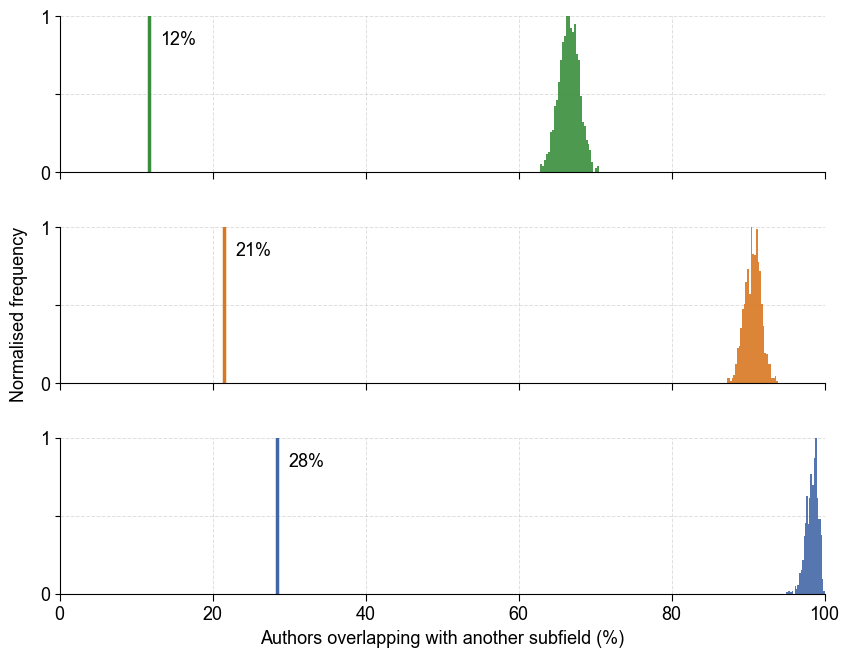

In [74]:

# ============================================================
# PLOT: AUTHOR OVERLAP PERMUTATION DISTRIBUTIONS (2+ PAPERS)
# THREE SUBFIELDS: ECOLOGY, EPIDEMIOLOGY, ONCOLOGY
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 11,
    "axes.labelsize": 13,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 11,
    "pdf.fonttype": 42,
})


def plot_author_permutation_results_3fields(
    author_permutation_results_3fields,
    observed_author_overlap_3fields,
):

    # ---------------------------------------------
    # Create three vertically stacked panels
    # ---------------------------------------------

    fig, axes = plt.subplots(
        3, 1,
        figsize=(9, 7.5),
        sharex=True
    )

    # ---------------------------------------------
    # Plot each subfield separately
    # ---------------------------------------------

    for i, field in enumerate(AUTHOR_FIELDS_3fields):

        ax = axes[i]

        null_values = np.asarray(
            author_permutation_results_3fields[field]
        )

        observed = observed_author_overlap_3fields[field]

        # ---------------------------------------------
        # Permutation distribution (normalised)
        # ---------------------------------------------

        counts, bin_edges = np.histogram(
            null_values,
            bins=30
        )

        ax.hist(
            null_values,
            bins=bin_edges,
            weights=np.ones(len(null_values)) / counts.max(),
            color=colour_map[field],
            alpha=0.9
        )

        # ---------------------------------------------
        # Observed author overlap
        # ---------------------------------------------

        ax.axvline(
            observed,
            color=colour_map[field],
            linewidth=2.5,
            linestyle="-"
        )

        # Add observed percentage beside the line
        ax.annotate(
            f"{observed:.0f}%",
            xy=(observed, 0.85),
            xycoords=("data", "axes fraction"),
            xytext=(8, 0),
            textcoords="offset points",
            ha="left",
            va="center",
            fontsize=13,
            color="black",
            #fontweight="bold"
        )

        """
        # ---------------------------------------------
        # Subfield label on the left
        # ---------------------------------------------

        ax.set_ylabel(
            field.capitalize(),
            rotation=0,
            ha="right",
            va="center",
            labelpad=20,
            fontsize=12
        )
        """

        # ---------------------------------------------
        # Format axes
        # ---------------------------------------------

        ax.set_xlim(0, 100)

        # Y-axis: normalised frequency
        ax.set_ylim(0, 1)
        ax.set_yticks([0, 0.5, 1])
        ax.set_yticklabels(["0", "", "1"])

        ax.tick_params(
            axis="y",
            left=True,
            labelleft=True,
            labelsize=13
        )

        # ---------------------------------------------
        # Remove unnecessary borders
        # ---------------------------------------------

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        # Keep left and bottom axes black
        ax.spines["left"].set_visible(True)
        ax.spines["left"].set_color("black")
        ax.spines["left"].set_linewidth(0.8)

        ax.spines["bottom"].set_visible(True)
        ax.spines["bottom"].set_color("black")
        ax.spines["bottom"].set_linewidth(0.8)

        # ---------------------------------------------
        # X-axis ticks on ALL panels
        # ---------------------------------------------

        ax.set_xticks(range(0, 101, 20))

        ax.tick_params(
            axis="x",
            which="major",
            bottom=True,
            labelbottom=(i == len(AUTHOR_FIELDS_3fields) - 1),
            length=5,
            width=0.8,
            labelsize=13
        )

        # ---------------------------------------------
        # Faint horizontal grid lines
        # ---------------------------------------------

        ax.set_axisbelow(True)

        ax.yaxis.grid(
            True,
            linestyle="--",
            color="grey",
            alpha=0.25,
            linewidth=0.7
        )

        # ---------------------------------------------
        # Faint vertical grid lines
        # ---------------------------------------------

        ax.xaxis.grid(
            True,
            linestyle="--",
            color="grey",
            alpha=0.25,
            linewidth=0.7
        )

    # ---------------------------------------------
    # Shared axis labels
    # ---------------------------------------------

    axes[-1].set_xlabel(
        "Authors overlapping with another subfield (%)",
        fontsize=13,
    )

    fig.text(
        0.055,
        0.54,
        "Normalised frequency",
        rotation=90,
        fontsize=13,
        ha="center",
        va="center"
    )

    # ---------------------------------------------
    # Layout and save
    # ---------------------------------------------

    plt.subplots_adjust(
        left=0.10,
        right=0.95,
        top=0.9361,
        bottom=0.1662,
        hspace=0.35
    )

    fig.savefig(
        ORCID_OUTPUT_DIR /
        "author_overlap_permutation_distributions_min2_3fields.pdf",
        bbox_inches="tight"
    )

    plt.show()


plot_author_permutation_results_3fields(
    author_permutation_results_3fields,
    observed_author_overlap_3fields,
)
